# Show a solution, ban it, see what replaces it

**Exposure-ban experiment (Step 1b) on Qwen3-8B, re-run as a CPU demo of its frozen analysis**

**The question.** Show a language model a correct program that uses algorithm **Y**, then forbid Y. What does it write instead?
- *Subtraction*: the ban only removes Y. The model falls back to what it would have written anyway: its context-free **default**, or whatever remains once Y's surface tokens are removed.
- *Substitution*: the ban steers the model to a specific alternative, either its own idea of "the standard alternative to Y" or the algorithm structurally closest to the code it was shown.

For the broader question of whether prompting can push a model toward *different* solutions, this tells us where a ban actually sends the model.

**Design** (Qwen3-8B, bf16, thinking off, vLLM 0.11.0, revision `b968826d`):
- 12 frozen tasks of the exp11 algorithm-choice bench (two-sum, k-th smallest, substring search, connected components, LIS, ...). Each task has a catalogue of algorithms ("modes") and a context-free default.
- For each of the 33 non-default algorithms Y with a correct forced program, the prompt shows up to 5 name-scrubbed correct programs of Y and then asks one of the instructions below. 19 of the 33 are *priority* Y, whose frozen associate differs from the default.

  | arm | instruction after the shown program(s) |
  |---|---|
  | COPY (matched twin) | `Write a correct solution.` |
  | NAMED (= template W5) | `Write a correct solution that does not use {Y}.` |
  | UNNAMED | `Write a correct solution that uses a different algorithm from the one above.` |

- N = 50 samples per Y and arm, with seeds shared across arms. Every program is labelled by the bench's gated labeller: hidden tests, a runtime-trace labeller and an AST labeller, plus a blind LLM judge where those two disagree.

**Four forecasts of the replacement**, committed in a sha256 hash chain *before any ban sample was drawn*:

| family | forecast of what replaces Y | account |
|---|---|---|
| **LADDER** | the model's context-free default | subtraction (ban-free) |
| **SUBTRACT-IN-CONTEXT** | the non-Y landing when Y's distinctive token n-gram is vetoed under the COPY prompt (vLLM logits processor, up to 3 rounds) | subtraction (ban-free) |
| **ASSOCIATE** | the model's own modal answer to "what is the standard alternative to Y?" | substitution |
| **PROXIMITY** | the surviving algorithm nearest the shown programs (Zhang-Shasha tree-edit distance on identifier-normalised ASTs) | substitution |

**What this notebook runs.** The original `method.py` drives eight subcommands.
- Four need the exp11 bench, the Qwen3-8B weights or an NVIDIA GPU: `setup`, `forecasts`, `stage1` and `stage2`. Generation took about 1 GPU-hour on an L4 and produced 10,600 labelled programs.
- The other four read and write the artifact's full data folder.

They are all shown below as code, but **none is called**.

Instead, the notebook re-runs the event-level part of the CPU **`analyze`** stage on the 66 committed events (33 Y x NAMED/UNNAMED) in `mini_demo_data.json`:
1. Re-score every event from its committed forecasts and its observed landing with the frozen `analysis/c1.py`, and check the result against the published values.
2. Run the frozen C1 forecast contest: advance rule, Holm-corrected paired Wilcoxon tests, task-cluster bootstrap CIs and the branch verdict.
3. Run the pre-registered sensitivities, the exploratory three-family contest, the placebos, and the unit-test null calibration of the advance rule.
4. Show the results as tables and figures.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru: NOT pre-installed on Colab (the original code logs with it), so always install it
_pip('loguru==0.7.3')

# numpy, scipy, matplotlib, pandas: pre-installed on Colab, so install them locally only, at Colab's versions
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'matplotlib==3.10.0', 'pandas==2.2.2')

In [2]:
from __future__ import annotations

# --- method.py ---
import argparse
import json
import math
import os
import resource
import subprocess
import sys
import tarfile
import time
from pathlib import Path

from loguru import logger
# from exposure.core import (COMMIT_LOG, DATA, LOGS, MODEL_ID, MODEL_REV, PRED, RESULTS, TASK_ORDER, Timer,
#                            deviation, read_json, read_jsonl, setup_logging, sha256_file, sha256_text, write_json)
#   -> notebook: exposure/core.py is inlined in section 1 below

# --- exposure/core.py, analysis/c1.py, analysis/events.py, exposure/report.py, exposure/figures.py ---
import hashlib
import random
import threading
from collections import Counter, defaultdict

import numpy as np
from scipy.stats import wilcoxon

# --- notebook additions: namespaces for the original module-qualified calls (c1.*, EV.*), tables, inline figures ---
import types

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_5eGZGmskluur/round-3/experiment-14/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
print(data["metadata"]["title"])
print({d["dataset"]: len(d["examples"]) for d in data["datasets"]})

GitHub data unavailable, using local mini_demo_data.json: <urlopen error [Errno 111] Connection refused>
Show a solution, ban it, see what replaces it (exposure-ban experiment, Qwen3-8B bf16)
{'exposure_events': 66}


## Configuration

Every tunable parameter is set here. The values below are the **original** ones. With them the whole notebook runs in about 20 s on a CPU, most of it in the install cell, and reproduces the published numbers exactly.
- `MAX_Y`: the data size, i.e. how many banned algorithms Y to analyse. Each Y gives one NAMED and one UNNAMED event. With fewer than about 15 Y, the primary paired tests are skipped by design, because the frozen rule needs at least 10 gated disagreeing events.
- `N_BOOT_*` and `N_*_DRAWS`: the resampling budgets. Smaller values run faster, but the task-cluster CIs and the placebo and calibration shares then no longer reproduce the published numbers exactly.

In [5]:
# Data size: banned algorithms Y to analyse, in the published (task) order; each Y gives a NAMED and an UNNAMED event
MAX_Y = 33                    # original: 33 (all eligible Y = 66 events)

# Resampling budgets of the frozen analysis
N_BOOT_PRIMARY = 10_000       # task-cluster bootstrap resamples of the 4 primary paired tests (c1.N_BOOT; original 10_000)
N_BOOT_SECONDARY = 2_000      # resamples in the sensitivities, three-family contest and rotation placebo (original 2_000)
N_PERMUTATION_DRAWS = 200     # label-permutation placebo draws (original 200)

# Null calibration of the advance rule (tests/test_unit.py, T1(f))
N_CALIB_DRAWS = 200           # simulated 15-event experiments per scenario (original 200)
N_CALIB_BOOT_PLANTED = 200    # bootstrap resamples per planted-scenario run (original 200)
N_CALIB_BOOT_NULL = 50        # bootstrap resamples per null-scenario run (original 50)

## The data: 66 committed exposure events

An **event** is one (banned algorithm Y, ban wording) pair, built from the 50 labelled programs of that arm. Each row of the `exposure_events` dataset carries:
- `input`: the task, the banned Y, the exact ban wording, and the sha256 hashes of the shown programs.
- `metadata_landing_counts`: the observed **non-Y landing**, i.e. the labels of the attempts that did *not* use Y. Survivors keep their name; anything outside the catalogue counts as `other`.
- `metadata_n_attempts`, `metadata_n_nonY`, `metadata_avoidance` (1 − share of attempts still labelled Y) and `metadata_correct_counts` (the non-Y landing restricted to programs that pass the hidden tests).
- `metadata_forecasts`: the four committed forecast distributions over the survivors. `null` means undefined, which is scored as uniform.
- `metadata_survivors`: the survivor set S, i.e. the task's catalogue minus Y. `metadata_proximity_token_distance` is the token-distance variant of PROXIMITY, used by one sensitivity.
- The published outputs: `output` (modal replacement), `predict_*` (each family's top-1), `metadata_logscore`, `metadata_hit`, `metadata_gate_pass`, `metadata_disagreeing`.

The cell below keeps the first `MAX_Y` banned algorithms, shows a few events, and prints one exact prompt the model saw.

In [6]:
# Notebook: keep the first MAX_Y banned algorithms (both of their events), in the published (task) order
examples_all = next(d for d in data["datasets"] if d["dataset"] == "exposure_events")["examples"]


def _yk(ex):
    inp = json.loads(ex["input"])
    return f"{inp['task']}:{inp['banned_Y']}"


keys_sel = list(dict.fromkeys(_yk(ex) for ex in examples_all))[:MAX_Y]
examples = [ex for ex in examples_all if _yk(ex) in keys_sel]
print(f"{len(keys_sel)} banned algorithms Y -> {len(examples)} events "
      f"({sum(ex['metadata_event_type'] == 'exposure_named' for ex in examples)} NAMED, "
      f"{sum(ex['metadata_event_type'] == 'exposure_unnamed' for ex in examples)} UNNAMED)")

pd.set_option("display.max_colwidth", 70)
display(pd.DataFrame([{
    "task": json.loads(ex["input"])["task"], "banned Y": json.loads(ex["input"])["banned_Y"],
    "arm": ex["metadata_event_type"].replace("exposure_", "").upper(), "wording": json.loads(ex["input"])["wording"],
    "avoidance": round(ex["metadata_avoidance"], 2), "non-Y attempts": ex["metadata_n_nonY"],
    "non-Y landing": ex["metadata_landing_counts"], "LADDER top-1": ex["predict_ladder"],
    "ASSOCIATE top-1": ex["predict_associate"], "PROXIMITY top-1": ex["predict_proximity"],
    "SUBTRACT top-1": ex["predict_subtract"]} for ex in examples[:8]]))

example_prompts = data["metadata"].get("example_prompts", {})  # three rendered prompts of predictions/prompts.jsonl
if "T05:brute_force:named:p0" in example_prompts:
    print("Example prompt (T05 two-sum, Y = brute force, NAMED arm, shown program p0):\n")
    print(example_prompts["T05:brute_force:named:p0"])

33 banned algorithms Y -> 66 events (33 NAMED, 33 UNNAMED)


,task,banned Y,arm,wording,avoidance,non-Y attempts,non-Y landing,LADDER top-1,ASSOCIATE top-1,PROXIMITY top-1,SUBTRACT top-1
0,T03,size_k_heap,NAMED,Write a correct solution that does not use a size-k heap.,0.2,10,{'full_sort': 10},full_sort,quickselect,heapify_pop,counting_sort|full_sort|heapify_pop|median_of_medians|quickselect
1,T03,size_k_heap,UNNAMED,Write a correct solution that uses a different algorithm from the ...,1.0,50,{'full_sort': 50},full_sort,quickselect,heapify_pop,counting_sort|full_sort|heapify_pop|median_of_medians|quickselect
2,T03,heapify_pop,NAMED,Write a correct solution that does not use heapify-and-pop.,1.0,50,"{'quickselect': 45, 'full_sort': 5}",full_sort,quickselect,full_sort,counting_sort|full_sort|median_of_medians|quickselect|size_k_heap
3,T03,heapify_pop,UNNAMED,Write a correct solution that uses a different algorithm from the ...,1.0,50,"{'full_sort': 35, 'quickselect': 15}",full_sort,quickselect,full_sort,counting_sort|full_sort|median_of_medians|quickselect|size_k_heap
4,T03,quickselect,NAMED,Write a correct solution that does not use quickselect.,1.0,50,{'full_sort': 50},full_sort,heapify_pop,median_of_medians,counting_sort|full_sort|heapify_pop|median_of_medians|size_k_heap
5,T03,quickselect,UNNAMED,Write a correct solution that uses a different algorithm from the ...,1.0,50,"{'full_sort': 42, 'size_k_heap': 8}",full_sort,heapify_pop,median_of_medians,counting_sort|full_sort|heapify_pop|median_of_medians|size_k_heap
6,T03,median_of_medians,NAMED,Write a correct solution that does not use median of medians.,1.0,50,{'quickselect': 50},full_sort,quickselect,quickselect,quickselect
7,T03,median_of_medians,UNNAMED,Write a correct solution that uses a different algorithm from the ...,1.0,50,"{'quickselect': 45, 'full_sort': 5}",full_sort,quickselect,quickselect,quickselect


Example prompt (T05 two-sum, Y = brute force, NAMED arm, shown program p0):

Here is a correct solution to this task:

```python
def solve(nums, target):
    for i in range(len(nums)):
        for j in range(i + 1, len(nums)):
            if nums[i] + nums[j] == target:
                return [i, j]
```

Write a correct solution that does not use a brute-force double loop.

Task: write a Python function solve(nums, target) that returns a list [i, j] of two indices with i < j such that nums[i] + nums[j] == target. The argument nums is a list of integers with 2 <= len(nums) <= 2000 and every value between -10**9 and 10**9 inclusive; target is an integer. Each input has exactly one pair of indices whose values add up to target, so the answer is unique. The two indices must be different positions, although the values at them may be equal.

Use only the Python standard library. Return only one ```python code block containing the function solve and any helpers, with no example usage and no e

## 1. Frozen constants and helpers (`exposure/core.py`)

The design constants:
- model and revision, and the seeds;
- N = 50 programs per (Y, arm), and at most 5 shown programs of at most 600 tokens each;
- the veto parameters: n-grams of up to 6 tokens, up to 3 rounds, and at least 20 non-Y attempts for SUBTRACT to be defined;
- the exact wordings of the three arms and of the four extra ban templates W1–W4.

`seed_of` implements **common random numbers**: sample *j* for shown program *i* uses `sha256("task:Y:p{i}:s{j}")` as its seed. COPY, every veto round, NAMED, UNNAMED and W1–W4 share that seed, so differences between arms are not differences in the random seed.

Notebook changes: `ROOT` is the current directory, because a notebook has no `__file__`. The exp11 bench location (`EXP11`) is commented out, since only `setup` reads it. Logging goes to the cell output only.

In [7]:
"""Shared constants, paths, logging, hashing and IO helpers for the exposure-ban experiment.

Every path is derived from the workspace root (the directory holding method.py).  The exp11 bench is read once,
by `method.py setup`, from EXP11_DIR (default: the sibling iteration-2 artifact, located relative to this
workspace) and copied into ./bench_copy/; nothing is ever written outside the workspace.
"""

ROOT = Path.cwd()  # notebook: no __file__; in the artifact ROOT = Path(__file__).resolve().parent.parent
# EXP11 = Path(os.environ.get("EXP11_DIR") or (ROOT.parents[2] / "iter_2" / "gen_art" / "gen_art_experiment_11"))
#   notebook: only `setup` reads the exp11 bench, which this demo does not run
BENCH = ROOT / "bench_copy"
DATA = ROOT / "data"
PRED = ROOT / "predictions"
RESULTS = ROOT / "results"
FIGS = ROOT / "figures"
LOGS = ROOT / "logs"
COMMIT_LOG = ROOT / "commitments.log"

MODEL_ID = "Qwen/Qwen3-8B"
MODEL_REV = "b968826d9c46dd6066d109eabc6255188de91218"  # the main revision on 2026-10-20; exp8 used b968826d
DTYPE = "bfloat16"
BASE_SEED = 20261020
SHUFFLE_SEED = 20261020  # committed seed of the shown-program shuffle and the proximity reference selection

# Stage-A order of the 12 frozen tasks (exp11 commitments.log, stageA_order minus the excluded R2)
TASK_ORDER = ["T03", "T04", "T06", "T05", "T10", "R1", "T08", "R3", "T13", "R6", "T14", "T11"]

N_PER_ARM = 50
MAX_SHOWN = 5
MAX_SHOWN_TOKENS = 600
NGRAM_MAX = 6
PRESENCE_MIN = 0.8
COVETO_SHARE = 0.5
REEMERGE_MIN = 0.20
MAX_ROUNDS = 3
MIN_NONY_SUBTRACT = 20
N_BASELINE_CHECK = 20
MAX_MODEL_LEN = 2048
MAX_NEW_TOKENS = 1024
JUDGE_SOFT_CAP = 0.50  # stop new judge calls (USD); the hard cap of the plan is 0.60

NL = "\n"
INTRO = "Here is a correct solution to this task:"
WORDINGS = {
    "copy": "Write a correct solution.",
    "named": "Write a correct solution that does not use {x}.",  # = frozen template W5
    "unnamed": "Write a correct solution that uses a different algorithm from the one above.",
}
# Frozen ban templates W1-W4 of the shared protocol (round-2 prompts_v2.json); W5 is the NAMED wording above.
TEMPLATES_W1_W4 = {
    "W1": "Do not use {x} for this task.",
    "W2": "Your solution must not rely on {x}.",
    "W3": "Avoid {x} entirely.",
    "W4": "{x} is not allowed here.",
}

In [8]:
def setup_logging(name: str) -> None:
    LOGS.mkdir(parents=True, exist_ok=True)
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    logger.add(LOGS / f"{name}.log", rotation="30 MB", level="DEBUG")


def ensure_bench_importable() -> None:
    if str(ROOT) not in sys.path:
        sys.path.insert(0, str(ROOT))


def sha256_text(s: str) -> str:
    return hashlib.sha256(s.encode("utf-8")).hexdigest()


def sha256_file(p: Path) -> str:
    h = hashlib.sha256()
    with Path(p).open("rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def canon_json(obj) -> str:
    return json.dumps(obj, sort_keys=True, separators=(",", ":"), ensure_ascii=False)


def seed_of(key: str) -> int:
    """Seed shared by every arm of one (task, Y, shown program, sample index): common random numbers."""
    return int(sha256_text(key)[:8], 16)


def read_jsonl(p: Path) -> list[dict]:
    if not Path(p).exists():
        return []
    out = []
    with Path(p).open() as f:
        for line in f:
            line = line.strip()
            if line:
                out.append(json.loads(line))
    return out


_write_lock = threading.Lock()


def append_jsonl(p: Path, rows: list[dict]) -> None:
    with _write_lock, Path(p).open("a") as f:
        for r in rows:
            f.write(json.dumps(r) + "\n")
        f.flush()


def write_json(p: Path, obj, indent: int = 1) -> None:
    Path(p).parent.mkdir(parents=True, exist_ok=True)
    Path(p).write_text(json.dumps(obj, indent=indent, default=_json_default))


def _json_default(o):
    if hasattr(o, "item"):
        return o.item()
    if isinstance(o, (set, tuple)):
        return list(o)
    raise TypeError(f"not JSON serialisable: {type(o)}")


def read_json(p: Path):
    return json.loads(Path(p).read_text())


def task_dir(task: str) -> Path:
    for d in BENCH.iterdir():
        if d.is_dir() and d.name.split("_")[0] == task:
            return d
    raise FileNotFoundError(f"no bench dir for {task}")


def load_spec(task: str) -> dict:
    return read_json(task_dir(task) / "spec.json")


def fenced(code: str) -> str:
    """The exact fenced text used for n-gram tokenisation and for the shown-program prompt block."""
    return "```python" + NL + code.rstrip() + NL + "```"


def wilson(k: int, n: int, z: float = 1.959964) -> tuple[float, float]:
    if n == 0:
        return (float("nan"), float("nan"))
    p = k / n
    d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return (max(0.0, c - h), min(1.0, c + h))


class Timer:
    """Accumulates wall and GPU seconds per stage into results/timings.json."""

    path = RESULTS / "timings.json"

    def __init__(self, stage: str, gpu: bool = False):
        self.stage, self.gpu = stage, gpu

    def __enter__(self):
        self.t0 = time.time()
        return self

    def __exit__(self, *exc):
        dt = time.time() - self.t0
        RESULTS.mkdir(exist_ok=True)
        tm = read_json(self.path) if self.path.exists() else {}
        e = tm.setdefault(self.stage, {"wall_s": 0.0, "gpu_s": 0.0, "runs": 0})
        e["wall_s"] += dt
        e["gpu_s"] += dt if self.gpu else 0.0
        e["runs"] += 1
        e["last_end_utc"] = time.strftime("%Y-%m-%dT%H:%M:%SZ", time.gmtime())
        write_json(self.path, tm)
        logger.info(f"[timing] {self.stage}: {dt:.1f}s ({'GPU' if self.gpu else 'CPU'})")
        return False


def load_tokenizer():
    from transformers import AutoTokenizer
    return AutoTokenizer.from_pretrained(MODEL_ID, revision=MODEL_REV)


def deviation(text: str) -> None:
    """Record a declared deviation from the plan (results/deviations.jsonl), deduplicated by text."""
    p = RESULTS / "deviations.jsonl"
    RESULTS.mkdir(exist_ok=True)
    have = {r["text"] for r in read_jsonl(p)}
    if text not in have:
        append_jsonl(p, [{"ts": time.strftime("%Y-%m-%dT%H:%M:%SZ", time.gmtime()), "text": text}])
        logger.warning(f"DEVIATION: {text}")


# notebook: log to the cell output only (setup_logging() would also open a file sink under logs/)
logger.remove()
logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")

# common random numbers: one seed per (task, Y, shown program, sample index), shared by every arm
print("seed_of('T03:size_k_heap:p0:s0') =", seed_of("T03:size_k_heap:p0:s0"),
      "(the published sample T03:size_k_heap:copy:r0:p0:s0 was drawn with seed 1050919540)")
print("the three arms:", json.dumps({k: v.format(x="{Y}") for k, v in WORDINGS.items()}, indent=1))

seed_of('T03:size_k_heap:p0:s0') = 1050919540 (the published sample T03:size_k_heap:copy:r0:p0:s0 was drawn with seed 1050919540)
the three arms: {
 "copy": "Write a correct solution.",
 "named": "Write a correct solution that does not use {Y}.",
 "unnamed": "Write a correct solution that uses a different algorithm from the one above."
}


## 2. `method.py`: the pipeline driver

`method.py` is a command-line driver. Its subcommands run in this order; each reads what the previous one wrote, and two hash commitments bracket the generation.

| subcommand | what it does | needs | original runtime |
|---|---|---|---|
| `setup` | copies and sha256-verifies the exp11 bench (158 hashes); re-checks the labeller on 320 gold programs; defaults; eligibility (33 Y, 19 priority); COMMIT #0 | exp11 bench | 1.6 min |
| `forecasts` | shown-program pools (scrub → hidden tests → relabel → canonical-token dedup → ≤ 600 tokens); distinctive n-gram g\*; allocation; PROXIMITY (2,972 Zhang-Shasha pairs); LADDER; ASSOCIATE; 775 rendered prompts | bench + Qwen3 tokenizer | 9 min |
| `commit1` | the 11 unit tests must pass; tars `analysis/` + `tests/`; **COMMIT #1** of every forecast, prompt and the analysis code | artifact folder | ~2 min |
| `stage1` | GPU smoke tests of the veto logits processor; COPY twin; veto rounds 1–3; bf16 baseline check → SUBTRACT-IN-CONTEXT | vLLM + GPU | 20 GPU-min (L4) |
| `commit2` | **COMMIT #2** (SUBTRACT, veto rounds, copy twin, baseline check); refuses if any ban sample already exists | artifact folder | < 1 min |
| `stage2` | NAMED + UNNAMED bans (3,300 programs), then the W1–W4 template arm (760) | vLLM + GPU | 14.5 GPU-min |
| `analyze` | per-sample table, events, **frozen C1** + sensitivities + placebos, reports, figures, `method_out.json` | artifact folder | 12 s |
| `audit` | independent re-derivation of all 66 events (0 mismatches); placebos; hash-chain verification | artifact folder | ~1 min |

The next cells are `method.py` itself, split by stage. There are two changes, both needed in a notebook:
- the module-level `from exposure.core import ...` is replaced by the section-1 cells;
- the final `if __name__ == "__main__": main()` is dropped, because in a notebook `__name__` is `"__main__"` and `argparse` would parse the kernel's own arguments.

The first cell runs `env_info()`. The subcommand cells only **define** functions; nothing in them is called.

In [9]:
#!/usr/bin/env python3
"""Show a solution, ban it, see what replaces it: Step-1b exposure-ban experiment on Qwen3-8B (bf16, thinking off).

For every non-default algorithm Y of the 12 frozen exp11 bench tasks that has a correct forced program, the prompt shows
up to 5 name-scrubbed correct programs of Y and then asks COPY 'Write a correct solution.', NAMED '... that does not
use {Y}.' or UNNAMED '... uses a different algorithm from the one above.'.  Ban-free forecasts are fixed first
(LADDER = default, ASSOCIATE = modal frozen 'standard alternative to Y', PROXIMITY = nearest survivor by Zhang-Shasha
distance, SUBTRACT-IN-CONTEXT = the non-Y landing under an iterated persistent signature veto of Y's distinctive
token n-gram under the copy-twin prompt) and sha256 hash-chained before any ban sample is drawn.

Subcommands (run in this order):
  setup      copy + verify the exp11 bench, labeller re-check, defaults, eligibility           (CPU)
  forecasts  shown pools, n-grams, allocation, PROXIMITY, LADDER, ASSOCIATE, rendered prompts   (CPU)
  commit1    unit tests must pass; COMMIT #1 of every forecast, prompt and the analysis code    (CPU)
  stage1     GPU smoke tests, COPY twin, veto rounds 1-3, bf16 baseline check; SUBTRACT          (GPU)
  commit2    COMMIT #2 (SUBTRACT-IN-CONTEXT, veto rounds, copy-twin, baseline check)            (CPU)
  stage2     NAMED + UNNAMED exposure bans (+ optional W1-W4 template arm)                       (GPU)
  analyze    per-arm stats, events, frozen C1 scoring + advance rule + tests, reports, figures   (CPU)
  audit      independent re-derivation (audit/rederive.py), placebo, chain verification         (CPU)
"""

# ROOT = Path(__file__).resolve().parent   -> notebook: ROOT = Path.cwd(), set in the exposure/core.py cell
sys.path.insert(0, str(ROOT))
os.environ["PYTHONPATH"] = str(ROOT) + (os.pathsep + os.environ["PYTHONPATH"] if os.environ.get("PYTHONPATH") else "")


def _detect_cpus() -> int:
    try:
        q = int(Path("/sys/fs/cgroup/cpu/cpu.cfs_quota_us").read_text())
        p = int(Path("/sys/fs/cgroup/cpu/cpu.cfs_period_us").read_text())
        if q > 0:
            return math.ceil(q / p)
    except (FileNotFoundError, ValueError):
        pass
    try:
        parts = Path("/sys/fs/cgroup/cpu.max").read_text().split()
        if parts[0] != "max":
            return math.ceil(int(parts[0]) / int(parts[1]))
    except (FileNotFoundError, ValueError, IndexError):
        pass
    return len(os.sched_getaffinity(0))


NUM_CPUS = _detect_cpus()
ABORTED_STAGE1_MIN = 26  # wall minutes of the first stage-1 attempt, stopped for the stop-token bug (logs/stage1_attempt1_*)


def _cpu_ram_limit(gb: float) -> None:
    """Hard address-space cap for CPU-only subcommands (never for the CUDA process: it reserves huge VA ranges)."""
    resource.setrlimit(resource.RLIMIT_AS, (int(gb * 1024**3), int(gb * 1024**3)))


def env_info() -> dict:
    info = {"python": sys.version.split()[0], "num_cpus_cgroup": NUM_CPUS, "model": MODEL_ID, "model_revision": MODEL_REV}
    try:
        info["nvidia_smi"] = subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total,driver_version",
                                             "--format=csv,noheader"], capture_output=True, text=True,
                                            timeout=30).stdout.strip()
    except (OSError, subprocess.TimeoutExpired) as e:
        info["nvidia_smi"] = f"unavailable: {e}"
    for m in ["torch", "vllm", "transformers", "scipy", "numpy", "zss", "rapidfuzz"]:
        try:
            info[m] = __import__(m).__version__
        except (ImportError, AttributeError):
            info[m] = None
    return info


# notebook: print the environment record that `setup` writes to results/environment.json
# (the original run: Python 3.12.14, 6 CPUs, NVIDIA L4, torch 2.8.0, vllm 0.11.0; nothing here needs a GPU)
print(json.dumps(env_info(), indent=1))

{
 "python": "3.12.14",
 "num_cpus_cgroup": 2,
 "model": "Qwen/Qwen3-8B",
 "model_revision": "b968826d9c46dd6066d109eabc6255188de91218",
 "nvidia_smi": "unavailable: [Errno 2] No such file or directory: 'nvidia-smi'",
 "torch": null,
 "vllm": null,
 "transformers": null,
 "scipy": "1.16.3",
 "numpy": "2.0.2",
 "zss": null,
 "rapidfuzz": null
}


### CPU preparation: `setup` → `forecasts` → `commit1`

Everything the bans will be scored against is fixed here, **before any generation**:
- **`setup`** verifies the frozen bench and re-checks the labeller. It records each task's context-free **default** (the LADDER forecast) and each Y's **associate**, the modal frozen answer to "what is the standard alternative to Y?" (the ASSOCIATE forecast).
- **`forecasts`** builds the pool of shown programs and picks Y's distinctive token n-gram g\*, the veto target. It also computes **PROXIMITY**: for each shown program, the survivor whose reference programs have the smallest median Zhang-Shasha distance (on identifier-normalised ASTs), weighted by how many samples each shown program gets. Finally it renders all 775 prompts.
- **`commit1`** refuses to freeze anything unless the unit tests pass. It then writes COMMIT #1: a sha256 hash chain over the forecasts, the prompts and a tarball of the analysis code (`analysis/`, `tests/`).

In [10]:
# method.py, continued (definitions only: setup/forecasts need the exp11 bench and the Qwen3 tokenizer,
# commit1 needs the artifact's tests/ and predictions/)
# ------------------------------------------------------------------------------------------------------- setup
def cmd_setup(args) -> None:
    from exposure.forecasts import copy_and_verify, defaults_and_eligibility, labeller_recheck
    _cpu_ram_limit(40)
    with Timer("setup"):
        info = env_info()
        logger.info(f"environment: {json.dumps(info)}")
        write_json(RESULTS / "environment.json", info)
        ver = copy_and_verify()
        from bench_copy.common.commit import commit, verify_chain
        if not COMMIT_LOG.exists() or not any(r["kind"] == "commit0_inputs" for r in read_jsonl(COMMIT_LOG)):
            payload = {"bench_commitment_combined_sha256": ver["combined_sha256"],
                       "uncommitted_inputs": ver["uncommitted_input_sha256"]}
            write_json(PRED / "commit0_inputs.json", payload)
            commit(COMMIT_LOG, "commit0_inputs", sha256_file(PRED / "commit0_inputs.json"),
                   {"file": "predictions/commit0_inputs.json"})
            assert verify_chain(COMMIT_LOG)
        rc = labeller_recheck(workers=NUM_CPUS)
        flagged = [t for t, v in rc.items() if v["flag"]]
        if flagged:
            deviation(f"labeller re-check flags tasks {flagged} (more than 5 points below gate.json or a reference "
                      "mislabelled); their events are sampled but reported outside the primary")
        elig = defaults_and_eligibility()
        elig["labeller_flagged_tasks"] = flagged
        write_json(PRED / "eligibility.json", elig)


# --------------------------------------------------------------------------------------------------- forecasts
def cmd_forecasts(args) -> None:
    from exposure.core import load_tokenizer
    from exposure.forecasts import allocation, ngrams_and_shown, proximity, render_prompts, shown_pools
    _cpu_ram_limit(40)
    with Timer("forecasts"):
        tok = load_tokenizer()
        elig = read_json(PRED / "eligibility.json")
        pools = shown_pools(elig, tok, workers=NUM_CPUS)
        write_json(RESULTS / "shown_pool_summary.json",
                   {k: {"n_R": v["n_R"], "n_pool": len(v["kept"]), "drops": v["drops"]} for k, v in pools.items()})
        ngrams, shown = ngrams_and_shown(elig, pools, tok)
        alloc = {k: allocation(len(v)) for k, v in shown.items()}
        prox = proximity(elig, shown, alloc, workers=NUM_CPUS)
        e_by = {f"{e['task']}:{e['Y']}": e for e in elig["eligible"]}
        ladder = {k: {e_by[k]["default"]: 1.0} for k in shown}
        assoc = {k: e_by[k]["associate"] for k in shown}
        cov = {k: {"coveto_groups": v["coveto_groups"], "coveto_modes": v["coveto_modes"],
                   "default_coveto": v["default_coveto"], "associate_coveto": v["associate_coveto"],
                   "n_ref_lt5": v["n_ref_lt5"]} for k, v in ngrams.items()}
        prompts = render_prompts(tok, shown)
        with (PRED / "shown_programs.jsonl").open("w") as f:
            for k, s_y in shown.items():
                for p in s_y:
                    f.write(json.dumps({"key": k, "task": k.split(":")[0], "Y": k.split(":")[1], "p_index": p["p_index"],
                                        "n_samples": alloc[k][p["p_index"]], "code": p["code"],
                                        "code_sha256": p["code_sha256"], "canon_sha256": p["canon_sha256"],
                                        "src_sample_id": p["src_sample_id"], "n_tokens": p["n_tokens"],
                                        "renamed": p["renamed"], "unscrubbed": p["unscrubbed"]}) + "\n")
        write_json(PRED / "ngrams.json", ngrams)
        write_json(PRED / "coveto.json", cov)
        write_json(PRED / "associate.json", assoc)
        write_json(PRED / "proximity.json", prox)
        write_json(PRED / "ladder.json", ladder)
        write_json(PRED / "allocation.json", alloc)
        with (PRED / "prompts.jsonl").open("w") as f:
            for r in prompts:
                f.write(json.dumps(r) + "\n")
        logger.info(f"forecasts written for {len(shown)} Y")


# ------------------------------------------------------------------------------------------------------ commit1
COMMIT1_FILES = ["eligibility.json", "shown_programs.jsonl", "ngrams.json", "coveto.json", "associate.json",
                 "proximity.json", "ladder.json", "allocation.json", "prompts.jsonl", "analysis_code.tar"]


def _tar_analysis_code() -> Path:
    out = PRED / "analysis_code.tar"
    with tarfile.open(out, "w", format=tarfile.GNU_FORMAT) as tf:
        for p in sorted((ROOT / "analysis").glob("*.py")) + sorted((ROOT / "tests").glob("*.py")):
            ti = tf.gettarinfo(str(p), arcname=str(p.relative_to(ROOT)))
            ti.mtime, ti.uid, ti.gid, ti.uname, ti.gname = 0, 0, 0, "", ""
            with p.open("rb") as fh:
                tf.addfile(ti, fh)
    return out


def _commit_files(kind: str, files: list[str]) -> str:
    from bench_copy.common.commit import commit, verify_chain
    hashes = {}
    for f in files:
        h = sha256_file(PRED / f)
        hashes[f] = h
        commit(COMMIT_LOG, f"{kind}:{f}", h, {"file": f"predictions/{f}"})
    bundle = sha256_text(json.dumps(hashes, sort_keys=True))
    rec = commit(COMMIT_LOG, kind, bundle, {"files": hashes})
    ok = verify_chain(COMMIT_LOG)
    logger.info(f"{kind}: {len(files)} files, bundle {bundle[:16]}..., chain verifies: {ok}")
    if not ok:
        raise RuntimeError("hash chain does not verify")
    return rec["sha256"]


def cmd_commit1(args) -> None:
    if any(r["kind"] == "COMMIT1" for r in read_jsonl(COMMIT_LOG)):
        logger.info("COMMIT #1 already present; nothing to do")
        return
    r = subprocess.run([sys.executable, "-m", "pytest", "-q", "tests/"], cwd=ROOT, capture_output=True, text=True)
    (LOGS / "pytest_commit1.log").write_text(r.stdout + r.stderr)
    logger.info("pytest:\n" + r.stdout[-1500:])
    if r.returncode != 0:
        raise RuntimeError("unit tests fail; the analysis code cannot be frozen")
    _tar_analysis_code()
    _commit_files("COMMIT1", COMMIT1_FILES)

### GPU sampling: `stage1` → `commit2` → `stage2`

- **`stage1`** builds **SUBTRACT-IN-CONTEXT**, the "pure subtraction" counterfactual.
  - It keeps the COPY prompt, with no ban text, and forbids Y's distinctive token n-gram during decoding, through a vLLM V1 per-request logits processor (`exposure/veto.py`).
  - If Y re-emerges in ≥ 20% of attempts, the next round adds the new signature, up to 3 rounds.
  - The non-Y landing of the first round with ≥ 20 non-Y attempts is the SUBTRACT forecast. If no round gets there, SUBTRACT is *undefined* and is scored as uniform.
  - GPU smoke tests come first: the vetoed n-gram appears in 0/20 veto samples vs 20/20 COPY samples; an inert veto leaves 20/20 outputs identical; and veto/COPY twins diverge exactly at the vetoed position in 20/20.
- **`commit2`** freezes SUBTRACT, and refuses to run if a single ban sample already exists.
- **`stage2`** draws the bans: NAMED and UNNAMED, 50 samples per Y each, with the same seeds as COPY. Then it draws the optional W1–W4 template arm (10 samples × 19 priority Y × 4 templates).

Decoding everywhere: T = 1.0, top-p 1.0, no top-k, `max_tokens = min(1024, 2048 − prompt length)`, chat template with thinking disabled.

In [11]:
# method.py, continued (definitions only: stage1/stage2 need vLLM, the Qwen3-8B weights and an NVIDIA GPU)
def cmd_stage1(args) -> None:
    from exposure.stages import stage1
    if not any(r["kind"] == "COMMIT1" for r in read_jsonl(COMMIT_LOG)):
        raise RuntimeError("COMMIT #1 missing: no generation may happen before it")
    stage1(args)


COMMIT2_FILES = ["subtract_in_context.json", "veto_rounds.json", "copy_twin_summary.json", "bf16_baseline_check.json",
                 "optional_template_arm.json"]


def cmd_commit2(args) -> None:
    if any(r["kind"] == "COMMIT2" for r in read_jsonl(COMMIT_LOG)):
        logger.info("COMMIT #2 already present; nothing to do")
        return
    gens = read_jsonl(DATA / "generations.jsonl")
    bans = [g for g in gens if g["arm"] not in ("copy", "veto", "baseline")]
    if bans:
        raise RuntimeError(f"{len(bans)} ban samples exist before COMMIT #2: the design is void")
    _commit_files("COMMIT2", COMMIT2_FILES)


def cmd_stage2(args) -> None:
    from exposure.stages import stage2
    stage2(args)

### `analyze`, `audit` and the command line

- **`analyze`** (CPU, 12 s) turns the 10,600 labelled programs into per-(Y, arm) statistics and the 66 **events**. It runs the frozen C1 analysis on them and writes the reports, the figures and `method_out.json`. **Sections 3–6 of this notebook re-run its event-level part.**
- **`audit`** re-implements the scoring from scratch, without importing `analysis/`. It re-derives every event (0 mismatches over 66) and verifies the hash chain.

In [12]:
# method.py, continued (definitions only: analyze/audit read and write the full artifact folder)
def cmd_analyze(args) -> None:
    from exposure.report import analyze
    _cpu_ram_limit(40)
    with Timer("analyze"):
        analyze(args)


def cmd_audit(args) -> None:
    _cpu_ram_limit(40)
    with Timer("audit"):
        r = subprocess.run([sys.executable, "audit/rederive.py"], cwd=ROOT, capture_output=True, text=True)
        (LOGS / "audit.out").write_text(r.stdout + r.stderr)
        logger.info(r.stdout[-3000:])
        if r.returncode != 0:
            raise RuntimeError(f"audit failed: {r.stderr[-1500:]}")
        # fold the audit record into method_out.json (metadata), as the plan's 4.7 asks
        mo_path, red = ROOT / "method_out.json", read_json(RESULTS / "rederive.json")
        if mo_path.exists():
            mo = read_json(mo_path)
            md = mo["metadata"]
            md["audit_rederive"] = {k: red[k] for k in ("n_events_rederived", "n_mismatches", "headline", "placebo",
                                                        "chain_verifies", "committed_files_unchanged")}
            md["gpu_hours_note"] = (f"summary.gpu_hours ({md['summary']['gpu_hours']:.3f}) counts the completed stage-1 and "
                                    f"stage-2 runs; the aborted first stage-1 attempt (stop-token bug, about "
                                    f"{ABORTED_STAGE1_MIN} min) brings the total to about 1.0 GPU-hour on one NVIDIA L4")
            md["gpu_hours_including_aborted_attempt"] = round(md["summary"]["gpu_hours"] + ABORTED_STAGE1_MIN / 60, 3)
            md["exploratory_note"] = ("summary.exploratory_not_preregistered (three-family LADDER/ASSOCIATE/PROXIMITY "
                                      "contest) was added after the commits and is not part of the frozen C1 analysis")
            mo_path.write_text(json.dumps(mo))
            logger.info("audit record merged into method_out.json metadata")


COMMANDS = {"setup": cmd_setup, "forecasts": cmd_forecasts, "commit1": cmd_commit1, "stage1": cmd_stage1,
            "commit2": cmd_commit2, "stage2": cmd_stage2, "analyze": cmd_analyze, "audit": cmd_audit}


@logger.catch(reraise=True)
def main() -> None:
    ap = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    ap.add_argument("command", choices=sorted(COMMANDS))
    ap.add_argument("--max-num-seqs", type=int, default=64)
    ap.add_argument("--gpu-util", type=float, default=0.92)
    ap.add_argument("--label-workers", type=int, default=4)
    ap.add_argument("--no-template-arm", action="store_true")
    args = ap.parse_args()
    setup_logging(args.command)
    logger.info(f"=== method.py {args.command} (cpus={NUM_CPUS}) ===")
    COMMANDS[args.command](args)


# if __name__ == "__main__":
#     main()
# notebook: not called (in a notebook __name__ == "__main__" and argparse would read the kernel's own argv)
print("method.py subcommands defined (none is called in this demo):", ", ".join(COMMANDS))

method.py subcommands defined (none is called in this demo): setup, forecasts, commit1, stage1, commit2, stage2, analyze, audit


## 3. The frozen scoring rules (`analysis/c1.py`)

This file was hash-committed in COMMIT #1 **before any generation**, so the rules could not be tuned to the results. For one event (a banned Y under one ban wording):

- **Survivors** S are the task's catalogue minus Y. Every attempt that does not use Y is labelled with a survivor, or with `other`.
- **Smoothed forecast.** The raw forecast f is restricted to S ∪ {other} and renormalised; an undefined forecast becomes Uniform(S). Then
  q = 0.95·f + 0.05·Uniform(S), and p = 0.98·q + 0.02·δ_other.
  Every label therefore keeps a non-zero probability.
- **Log score** = the mean of ln p(label) over the non-Y attempts. Closer to 0 is better: a point forecast on the right survivor among 5 scores ln(0.98·0.96) ≈ −0.06 nats.
- **top-1** = the argmax of the raw forecast (ties kept). **hit** = the overlap of the top-1 set with the observed modal replacement.
- **disagreeing**: the four families' top-1 sets are not all equal.
- **gate**: avoidance ≥ 0.5 and at least 20 non-Y attempts, i.e. the ban was obeyed often enough to leave a landing to forecast.

In [13]:
"""Frozen C1 analysis code (hash-committed in COMMIT #1 before any generation).

Scoring (plan 4.3): survivor set S = catalogue minus Y; raw forecast f over S plus 'other';
  q = 0.95 f + 0.05 Uniform(S);  p = 0.98 q + 0.02 delta_other;  logscore_F = mean over non-Y attempts of ln p_F(label);
  top1_F = argmax of raw f (ties keep all tied labels); an undefined forecast is Uniform(S).
Event: modal label = argmax of the non-Y landing; hit_F = |top1_F & modal| / (|top1_F| |modal|);
  disagreeing = the four top-1 sets are not all equal; gate_pass = avoidance >= 0.5 and n_nonY >= 20.
Advance rule (4.4): on each gated disagreeing event, F wins if logscore_F - max_{G != F} logscore_G >= 0.10;
  F advances if it wins >= 3 events.  With >= 10 such events: four two-sided paired Wilcoxon signed-rank tests
  (zeros dropped = zero_method 'wilcox'; exact for n <= 25) on per-event log-score differences
  SUBTRACT-ASSOCIATE, SUBTRACT-PROXIMITY, LADDER-ASSOCIATE, LADDER-PROXIMITY, Holm-corrected over the 4, with
  task-cluster bootstrap 95% CIs (10,000 resamples) of the mean differences.
C1-exposure (4.5): JS (base 2) between NAMED and veto non-Y landings against a cluster-bootstrap null
  (clusters = shown program x arm, at the observed sizes; 2,000 pairs).
"""
# (imports of analysis/c1.py: math, random, Counter, numpy as np, scipy.stats.wilcoxon -> the imports cell)

FAMILIES = ["SUBTRACT", "LADDER", "ASSOCIATE", "PROXIMITY"]
BAN_FREE = ("SUBTRACT", "LADDER")
SUBSTITUTION = ("ASSOCIATE", "PROXIMITY")
TEST_PAIRS = [("SUBTRACT", "ASSOCIATE"), ("SUBTRACT", "PROXIMITY"), ("LADDER", "ASSOCIATE"), ("LADDER", "PROXIMITY")]
OTHER = "other"
W_FORECAST = 0.95
W_OTHER = 0.02
WIN_MARGIN = 0.10
MIN_WINS = 3
MIN_EVENTS_TESTS = 10
MIN_EVENTS_RULE = 3
GATE_AVOID = 0.5
GATE_NONY = 20
ALPHA = 0.05
N_BOOT = N_BOOT_PRIMARY  # original: 10_000 (set in the config cell)
N_NULL = 2_000
EXACT_MAX_N = 25


# ------------------------------------------------------------------------------------------------- distributions
def normalise_label(label: str, y: str, survivors: list[str]) -> str | None:
    """None for 'invalid' (not an attempt); Y and survivors unchanged; anything else ('other', 'unknown') -> 'other'."""
    if label == "invalid":
        return None
    if label == y or label in survivors:
        return label
    return OTHER


def clean_forecast(f: dict | None, survivors: list[str]) -> dict:
    """Restrict a raw forecast to S + 'other' and renormalise; undefined / empty -> Uniform(S)."""
    s = list(survivors)
    if f:
        g = {k: float(v) for k, v in f.items() if (k in s or k == OTHER) and v > 0}
        tot = sum(g.values())
        if tot > 0:
            return {k: v / tot for k, v in g.items()}
    return {k: 1.0 / len(s) for k in s}


def smooth(f: dict | None, survivors: list[str]) -> dict:
    s = list(survivors)
    k = len(s)
    g = clean_forecast(f, s)
    q = {x: W_FORECAST * g.get(x, 0.0) + (1.0 - W_FORECAST) / k for x in s}
    q[OTHER] = W_FORECAST * g.get(OTHER, 0.0)
    p = {x: (1.0 - W_OTHER) * v for x, v in q.items()}
    p[OTHER] += W_OTHER
    return p


def log_score(f: dict | None, survivors: list[str], counts: dict) -> float:
    """Mean ln p(label) over the non-Y attempts given as label counts (labels already normalised)."""
    p = smooth(f, survivors)
    n = sum(counts.values())
    if n == 0:
        return float("nan")
    return sum(c * math.log(p[lab]) for lab, c in counts.items()) / n


def top1(f: dict | None, survivors: list[str]) -> list[str]:
    g = clean_forecast(f, survivors)
    mx = max(g.values())
    return sorted(k for k, v in g.items() if abs(v - mx) < 1e-12)


def modal(counts: dict, restrict: list[str] | None = None) -> list[str]:
    c = {k: v for k, v in counts.items() if v > 0 and (restrict is None or k in restrict)}
    if not c:
        return []
    mx = max(c.values())
    return sorted(k for k, v in c.items() if v == mx)


def hit(t1: list[str], mod: list[str]) -> float:
    if not t1 or not mod:
        return 0.0
    return len(set(t1) & set(mod)) / (len(t1) * len(mod))


def is_disagreeing(top1s: dict[str, list[str]]) -> bool:
    return len({tuple(sorted(v)) for v in top1s.values()}) > 1


def js_divergence(a: dict, b: dict) -> float:
    """Jensen-Shannon divergence, base 2, between two count / probability dicts."""
    keys = sorted(set(a) | set(b))
    pa = np.array([a.get(k, 0.0) for k in keys], dtype=float)
    pb = np.array([b.get(k, 0.0) for k in keys], dtype=float)
    if pa.sum() == 0 or pb.sum() == 0:
        return float("nan")
    pa, pb = pa / pa.sum(), pb / pb.sum()
    m = 0.5 * (pa + pb)

    def kl(x, y):
        nz = x > 0
        return float(np.sum(x[nz] * np.log2(x[nz] / y[nz])))

    return 0.5 * kl(pa, m) + 0.5 * kl(pb, m)


def hill_shannon(counts: dict) -> float:
    n = sum(counts.values())
    if n == 0:
        return float("nan")
    return math.exp(-sum((c / n) * math.log(c / n) for c in counts.values() if c > 0))


# ------------------------------------------------------------------------------------------------------ events
def gate(avoidance: float, n_nony: int) -> bool:
    return (not math.isnan(avoidance)) and avoidance >= GATE_AVOID and n_nony >= GATE_NONY


def score_event(survivors: list[str], landing: dict, forecasts: dict[str, dict | None]) -> dict:
    """landing: normalised non-Y label counts; forecasts: family -> raw distribution (None = undefined)."""
    mod = modal(landing)
    t1 = {f: top1(forecasts.get(f), survivors) for f in FAMILIES}
    return {"modal": mod,
            "top1": t1,
            "logscore": {f: log_score(forecasts.get(f), survivors, landing) for f in FAMILIES},
            "hit": {f: hit(t1[f], mod) for f in FAMILIES},
            "disagreeing": is_disagreeing(t1),
            "unaimed": bool(mod) and all(not (set(mod) & set(t1[f])) for f in FAMILIES)}

### Advance rule, paired tests and branch verdict

Only **gated, disagreeing** events count: the forecasts must make different predictions, and the ban must have produced a landing to score.

- **Advance rule.** A family *wins* an event if its log score beats every other family's by ≥ 0.10 nats. It *advances* if it wins ≥ 3 events.
- **Paired tests.** With ≥ 10 such events, four two-sided paired Wilcoxon signed-rank tests compare a ban-free family with a substitution family on the per-event log-score differences: SUBTRACT − ASSOCIATE, SUBTRACT − PROXIMITY, LADDER − ASSOCIATE and LADDER − PROXIMITY.
  - They are Holm-corrected over the four.
  - The 95% CIs of the mean difference come from a **task-cluster bootstrap**: whole tasks are resampled, because the Y of one task share a default and a catalogue.
- **Branch.**
  - `SUBTRACTION/LADDER` if a ban-free family advances and no substitution family is Holm-significantly better.
  - `SUBSTITUTION` in the mirror case.
  - `MIXED` if both kinds advance.

In [14]:
# analysis/c1.py, continued
# ------------------------------------------------------------------------------------------------ advance rule
def advance_rule(events: list[dict], families: list[str] = FAMILIES) -> dict:
    wins = Counter()
    winners = []
    for ev in events:
        ls = ev["logscore"]
        w = None
        for f in families:
            others = [ls[g] for g in families if g != f]
            if ls[f] - max(others) >= WIN_MARGIN:
                wins[f] += 1
                w = f
        winners.append(w)
    adv = [f for f in families if wins[f] >= MIN_WINS]
    return {"n_events": len(events), "wins": {f: wins[f] for f in families}, "advancing": adv, "winners": winners}


def holm(pvals: list[float]) -> list[float]:
    m = len(pvals)
    order = sorted(range(m), key=lambda i: pvals[i])
    adj = [0.0] * m
    running = 0.0
    for rank, i in enumerate(order):
        running = max(running, min(1.0, (m - rank) * pvals[i]))
        adj[i] = running
    return adj


def wilcoxon_two_sided(d: list[float]) -> dict:
    nz = [x for x in d if x != 0]
    if not nz:
        return {"n": len(d), "n_nonzero": 0, "statistic": None, "p": 1.0, "method": "all-zero"}
    method = "exact" if len(nz) <= EXACT_MAX_N else "asymptotic"
    r = wilcoxon(nz, zero_method="wilcox", alternative="two-sided", method=method)
    return {"n": len(d), "n_nonzero": len(nz), "statistic": float(r.statistic), "p": float(r.pvalue), "method": method}


def cluster_bootstrap_mean(values: list[float], clusters: list[str], n_boot: int = N_BOOT, seed: int = 0) -> list[float]:
    """Percentile 95% CI of the mean, resampling clusters (tasks) with replacement."""
    by: dict[str, list[float]] = {}
    for v, c in zip(values, clusters):
        by.setdefault(c, []).append(v)
    keys = sorted(by)
    rng = random.Random(seed)
    means = []
    for _ in range(n_boot):
        vals = []
        for _k in keys:
            vals.extend(by[keys[rng.randrange(len(keys))]])
        means.append(sum(vals) / len(vals))
    return [float(np.quantile(means, 0.025)), float(np.quantile(means, 0.975))]


def paired_tests(events: list[dict], n_boot: int = N_BOOT, seed: int = 0) -> dict:
    if len(events) < MIN_EVENTS_TESTS:
        return {"run": False, "reason": f"{len(events)} < {MIN_EVENTS_TESTS} gated disagreeing events"}
    out = []
    for a, b in TEST_PAIRS:
        d = [ev["logscore"][a] - ev["logscore"][b] for ev in events]
        w = wilcoxon_two_sided(d)
        ci = cluster_bootstrap_mean(d, [ev["task"] for ev in events], n_boot=n_boot, seed=seed)
        out.append({"pair": f"{a}-{b}", "mean_diff": float(np.mean(d)), "median_diff": float(np.median(d)),
                    "ci95_task_cluster": ci, **w})
    adj = holm([r["p"] for r in out])
    for r, p in zip(out, adj):
        r["p_holm"] = p
        r["significant"] = p < ALPHA
        r["favours"] = (r["pair"].split("-")[0] if r["mean_diff"] > 0 else r["pair"].split("-")[1]) if r["significant"] else None
    return {"run": True, "tests": out}


def branch(rule: dict, tests: dict, unaimed_share: float, n_events: int) -> str:
    if n_events < MIN_EVENTS_RULE:
        return "UNDETERMINED"
    adv = set(rule["advancing"])
    adv_bf, adv_sub = adv & set(BAN_FREE), adv & set(SUBSTITUTION)
    fav = {r["favours"] for r in tests.get("tests", []) if r.get("significant")} if tests.get("run") else set()
    sig_bf, sig_sub = bool(fav & set(BAN_FREE)), bool(fav & set(SUBSTITUTION))
    if adv_bf and adv_sub:
        return "MIXED"
    if adv_bf and not sig_sub:
        return "SUBTRACTION/LADDER (" + "+".join(sorted(adv_bf)) + ")"
    if adv_sub and not sig_bf:
        return "SUBSTITUTION (" + "+".join(sorted(adv_sub)) + ")"
    if adv_bf or adv_sub:
        return "MIXED (advance contradicted by a Holm-significant test)"
    if unaimed_share >= 0.5:
        return "X-SPECIFIC BUT UNAIMED"
    return "NO FAMILY ADVANCES"


def run_c1(events: list[dict], n_boot: int = N_BOOT, seed: int = 0) -> dict:
    """events: dicts with task, gate_pass, disagreeing, logscore, unaimed.  Primary set = gated disagreeing."""
    sel = [e for e in events if e["gate_pass"] and e["disagreeing"]]
    rule = advance_rule(sel)
    tests = paired_tests(sel, n_boot=n_boot, seed=seed)
    unaimed = (sum(e["unaimed"] for e in sel) / len(sel)) if sel else float("nan")
    margins = []
    for e in sel:
        ls = e["logscore"]
        best = max(FAMILIES, key=lambda f: ls[f])
        margins.append({"Y": e.get("Y"), "task": e["task"], "best": best,
                        "margin": ls[best] - max(ls[g] for g in FAMILIES if g != best)})
    return {"n_events_total": len(events), "n_gated": sum(e["gate_pass"] for e in events),
            "n_gated_disagreeing": len(sel), "rule": rule, "tests": tests, "unaimed_share": unaimed,
            "branch": branch(rule, tests, unaimed if not math.isnan(unaimed) else 0.0, len(sel)),
            "margins": margins}

### C1-exposure and placebos

- **`c1_exposure`** compares, per shown program, where the NAMED ban lands with where the signature veto lands, using a JS divergence and a cluster-bootstrap null. It needs per-program labels, which the event table does not carry, so this notebook reports the published result instead. Only 2 events qualified.
- The **placebos** should *not* find an effect:
  - `placebo_rotation` hands every event the forecasts of another Y of the same task;
  - `placebo_permutation` relabels the survivors at random, with the same permutation for all four families.

  If a family still "advances" under them, the advance rule alone is weak evidence.

In [15]:
# analysis/c1.py, continued
# ------------------------------------------------------------------------------------------------- C1-exposure
def js_null(clusters_a: list[list[str]], clusters_b: list[list[str]], n_null: int = N_NULL, seed: int = 0) -> dict:
    """Cluster-bootstrap null of JS(A, B): pool the clusters of both arms, draw |A| and |B| clusters with replacement.
    With fewer than 4 pooled clusters the null resamples programs instead (flagged)."""
    rng = random.Random(seed)
    pool = [c for c in clusters_a + clusters_b if c]
    level = "cluster"
    if len(pool) < 4:
        level = "program"
        progs = [x for c in pool for x in c]
        na, nb = sum(len(c) for c in clusters_a), sum(len(c) for c in clusters_b)
        vals = []
        for _ in range(n_null):
            a = Counter(progs[rng.randrange(len(progs))] for _ in range(na))
            b = Counter(progs[rng.randrange(len(progs))] for _ in range(nb))
            vals.append(js_divergence(a, b))
    else:
        na, nb = len([c for c in clusters_a if c]), len([c for c in clusters_b if c])
        vals = []
        for _ in range(n_null):
            a, b = Counter(), Counter()
            for _k in range(na):
                a.update(pool[rng.randrange(len(pool))])
            for _k in range(nb):
                b.update(pool[rng.randrange(len(pool))])
            vals.append(js_divergence(a, b))
    vals = [v for v in vals if not math.isnan(v)]
    return {"q95": float(np.quantile(vals, 0.95)) if vals else float("nan"), "level": level, "n": len(vals)}


def c1_exposure(items: list[dict], n_null: int = N_NULL, seed: int = 0) -> dict:
    """items: one per gated NAMED event with keys Y, task, survivors, coveto (modes), associate_top1, subtract_dist,
    proximity_top1, default, named_clusters / veto_clusters (lists of per-shown-program non-Y label lists)."""
    rows = []
    for it in items:
        s = it["survivors"]
        sub_mod = modal({k: v for k, v in (it["subtract_dist"] or {}).items() if k in s})
        assoc = it["associate_top1"]
        if not assoc or (set(assoc) & set(sub_mod)):
            continue  # the associate does not differ from SUBTRACT's modal survivor
        if set(assoc) & set(it["coveto"]) or it["default"] in it["coveto"]:
            continue
        allowed = [x for x in s if x not in it["coveto"]]
        a = Counter(x for c in it["named_clusters"] for x in c)
        b = Counter(x for c in it["veto_clusters"] for x in c)
        ma, mb = modal(a, allowed), modal(b, allowed)
        agree = bool(set(ma) & set(mb))
        js = js_divergence(a, b)
        nul = js_null(it["named_clusters"], it["veto_clusters"], n_null=n_null, seed=seed)
        disc = bool(set(ma) & (set(assoc) | set(it["proximity_top1"]))) and not bool(set(mb) & (set(assoc) | set(it["proximity_top1"])))
        rows.append({"task": it["task"], "Y": it["Y"], "named_modal": ma, "veto_modal": mb, "agree": agree, "js": js,
                     "js_null_q95": nul["q95"], "null_level": nul["level"], "js_consistent": js <= nul["q95"],
                     "disconfirming": disc, "associate": assoc, "subtract_modal": sub_mod})
    n = len(rows)
    if n == 0:
        return {"n_events": 0, "verdict": "EMPTY", "rows": []}
    ag = sum(r["agree"] for r in rows) / n
    di = sum(r["disconfirming"] for r in rows) / n
    if ag >= 2 / 3 and di >= 1 / 3:
        verdict = "CONFIRM+DISCONFIRM (mixed)"
    elif ag >= 2 / 3:
        verdict = "CONFIRM"
    elif di >= 1 / 3:
        verdict = "DISCONFIRM"
    else:
        verdict = "NEITHER"
    return {"n_events": n, "agreement_share": ag, "disconfirm_share": di,
            "js_consistent_share": sum(r["js_consistent"] for r in rows) / n, "verdict": verdict, "rows": rows}


# ---------------------------------------------------------------------------------------------------- placebos
def rescore(events: list[dict], new_forecasts: list[dict]) -> list[dict]:
    out = []
    for ev, fc in zip(events, new_forecasts):
        sc = score_event(ev["survivors"], ev["landing_counts_norm"], fc)
        out.append({**ev, **sc, "forecasts": fc})
    return out


def placebo_rotation(events: list[dict]) -> dict:
    """Rotate every family's forecast across Y within each task (event i gets event i+1's forecasts)."""
    by: dict[str, list[int]] = {}
    for i, ev in enumerate(events):
        by.setdefault(ev["task"], []).append(i)
    new = [None] * len(events)
    skipped = []
    for t, idx in by.items():
        if len(idx) < 2:
            skipped.append(t)
            for i in idx:
                new[i] = None
            continue
        for k, i in enumerate(idx):
            new[i] = events[idx[(k + 1) % len(idx)]]["forecasts"]
    keep = [i for i in range(len(events)) if new[i] is not None]
    res = run_c1(rescore([events[i] for i in keep], [new[i] for i in keep]), n_boot=N_BOOT_SECONDARY)  # original: n_boot=2000
    return {"skipped_single_event_tasks": skipped, "n_events": len(keep), "advancing": res["rule"]["advancing"],
            "wins": res["rule"]["wins"], "branch": res["branch"], "n_gated_disagreeing": res["n_gated_disagreeing"]}


def placebo_permutation(events: list[dict], n_draws: int = 200, seed: int = 0) -> dict:
    """Relabel each event's survivors by a random permutation (same permutation for all four families)."""
    rng = random.Random(seed)
    adv_any, counts = 0, Counter()
    for _ in range(n_draws):
        fcs = []
        for ev in events:
            s = list(ev["survivors"])
            perm = s[:]
            rng.shuffle(perm)
            mp = dict(zip(s, perm))
            fcs.append({f: ({mp.get(k, k): v for k, v in (fc or {}).items()} if fc else None)
                        for f, fc in ev["forecasts"].items()})
        sc = rescore(events, fcs)
        sel = [e for e in sc if e["gate_pass"] and e["disagreeing"]]
        r = advance_rule(sel)
        adv_any += bool(r["advancing"])
        counts.update(r["advancing"])
    return {"n_draws": n_draws, "share_any_family_advances": adv_any / n_draws,
            "share_by_family": {f: counts[f] / n_draws for f in FAMILIES}}

The original modules call these functions as `c1.<name>` (`from analysis import c1`). The next cell gathers them into a `c1` namespace, so the downstream code runs verbatim.

It then runs three of the artifact's own unit tests (`tests/test_unit.py`), which check the scorer, Holm and the exact Wilcoxon on hand-computable inputs. Finally it scores one event by hand: an undefined SUBTRACT is uniform over the survivors, and a point forecast on the right survivor scores about −0.06 nats.

In [16]:
# Notebook glue: the original modules do `from analysis import c1` and call `c1.<name>`; collect the definitions above
c1 = types.SimpleNamespace(**{name: globals()[name] for name in [
    "FAMILIES", "BAN_FREE", "SUBSTITUTION", "TEST_PAIRS", "OTHER", "W_FORECAST", "W_OTHER", "WIN_MARGIN", "MIN_WINS",
    "MIN_EVENTS_TESTS", "MIN_EVENTS_RULE", "GATE_AVOID", "GATE_NONY", "ALPHA", "N_BOOT", "N_NULL", "EXACT_MAX_N",
    "normalise_label", "clean_forecast", "smooth", "log_score", "top1", "modal", "hit", "is_disagreeing",
    "js_divergence", "hill_shannon", "gate", "score_event", "advance_rule", "holm", "wilcoxon_two_sided",
    "cluster_bootstrap_mean", "paired_tests", "branch", "run_c1", "js_null", "c1_exposure", "rescore",
    "placebo_rotation", "placebo_permutation"]})


# tests/test_unit.py, (e) scorer and (f) Holm / exact Wilcoxon: hand-computable values
def test_scorer_values():
    s = ["a", "b", "c", "d"]
    k = len(s)
    p = c1.smooth({"a": 1.0}, s)
    assert abs(sum(p.values()) - 1) < 1e-12
    assert abs(math.log(p["a"]) - math.log(0.98 * (0.95 + 0.05 / k))) < 1e-12
    assert abs(math.log(p["b"]) - math.log(0.98 * 0.05 / k)) < 1e-12
    assert abs(c1.log_score({"a": 1.0}, s, {"a": 3}) - math.log(0.98 * (0.95 + 0.05 / k))) < 1e-12
    assert abs(c1.log_score({"a": 1.0}, s, {"b": 2}) - math.log(0.98 * 0.05 / k)) < 1e-12
    u = c1.smooth(None, s)
    assert all(abs(u[x] - 0.98 / k) < 1e-12 for x in s) and abs(u["other"] - 0.02) < 1e-12
    q = c1.smooth({"a": 0.5, "other": 0.5}, s)
    assert abs(sum(q.values()) - 1) < 1e-12 and abs(q["other"] - (0.98 * 0.95 * 0.5 + 0.02)) < 1e-12
    assert c1.top1(None, s) == s and c1.top1({"b": 0.6, "a": 0.4}, s) == ["b"]
    assert c1.top1({"b": 0.5, "a": 0.5}, s) == ["a", "b"]
    assert c1.is_disagreeing({"A": ["a"], "B": ["a"]}) is False and c1.is_disagreeing({"A": ["a"], "B": ["b"]})
    assert abs(c1.js_divergence({"a": 1}, {"b": 1}) - 1.0) < 1e-12 and c1.js_divergence({"a": 2}, {"a": 5}) == 0.0
    assert c1.normalise_label("unknown", "y", s) == "other" and c1.normalise_label("invalid", "y", s) is None


def test_holm():
    adj = c1.holm([0.01, 0.04, 0.03, 0.2])
    assert [round(x, 6) for x in adj] == [0.04, 0.09, 0.09, 0.2]


def test_wilcoxon_exact_small():
    r = c1.wilcoxon_two_sided([1.0, 2.0, 3.0, 4.0, 5.0, 6.0])
    assert r["method"] == "exact" and abs(r["p"] - 2 / 2 ** 6) < 1e-12


for _t in (test_scorer_values, test_holm, test_wilcoxon_exact_small):
    _t()
    print(f"{_t.__name__}: passed")

# Notebook: a worked example, i.e. how each family's forecast is scored on the first selected event
_ex = examples[0]
_inp = json.loads(_ex["input"])
print(f"\nWorked example: {_inp['task']} / banned Y = {_inp['banned_Y']} ({_ex['metadata_event_type']}); "
      f"survivors {_ex['metadata_survivors']}; observed non-Y landing {_ex['metadata_landing_counts']}")
for _f in c1.FAMILIES:
    _fc = _ex["metadata_forecasts"][_f]
    _sm = {k: round(v, 3) for k, v in c1.smooth(_fc, _ex["metadata_survivors"]).items()}
    _ls = c1.log_score(_fc, _ex["metadata_survivors"], _ex["metadata_landing_counts"])
    print(f"  {_f:9s} raw forecast {str(_fc):38s} -> smoothed p {_sm} -> log score {_ls:.3f} nats")

test_scorer_values: passed
test_holm: passed
test_wilcoxon_exact_small: passed

Worked example: T03 / banned Y = size_k_heap (exposure_named); survivors ['full_sort', 'heapify_pop', 'quickselect', 'median_of_medians', 'counting_sort']; observed non-Y landing {'full_sort': 10}
  SUBTRACT  raw forecast None                                   -> smoothed p {'full_sort': 0.196, 'heapify_pop': 0.196, 'quickselect': 0.196, 'median_of_medians': 0.196, 'counting_sort': 0.196, 'other': 0.02} -> log score -1.630 nats
  LADDER    raw forecast {'full_sort': 1.0}                     -> smoothed p {'full_sort': 0.941, 'heapify_pop': 0.01, 'quickselect': 0.01, 'median_of_medians': 0.01, 'counting_sort': 0.01, 'other': 0.02} -> log score -0.061 nats
  ASSOCIATE raw forecast {'quickselect': 1.0}                   -> smoothed p {'full_sort': 0.01, 'heapify_pop': 0.01, 'quickselect': 0.941, 'median_of_medians': 0.01, 'counting_sort': 0.01, 'other': 0.02} -> log score -4.625 nats
  PROXIMITY raw forecast {

## 4. From labelled programs to events (`analysis/events.py`)

`arm_stats` condenses the 50 labelled programs of one (Y, arm) into the statistics an event needs:
- `n_attempts` (programs that are not `invalid`) and `n_Y`;
- `avoidance` = 1 − n_Y / n_attempts;
- `landing_counts`, the non-Y attempts with labels normalised to a survivor or `other`;
- `correct_counts`, the same restricted to programs that pass the hidden tests;
- `default_share`.

`build_events` then scores every (Y, arm) with the frozen `c1.score_event` and `c1.gate`. `sensitivities` re-runs C1 under the pre-registered variants:
- SUBTRACT replaced by its top-1;
- per-pair contests;
- dropping events whose survivor is co-vetoed;
- priority Y only;
- token-distance PROXIMITY.

The file follows verbatim; it was also hash-committed in COMMIT #1. The demo data has no per-program rows, so `arm_stats`, `build_events`, `correct_only` and `exposure_items` are defined but not called.

In [17]:
"""Frozen event assembly (hash-committed in COMMIT #1): per-(Y, arm) statistics, exposure events, the primary C1 run
and its pre-registered sensitivities, and the C1-exposure inputs.  Pure functions over per-sample rows."""
# (imports of analysis/events.py: math, Counter, defaultdict -> the imports cell; `from . import c1` -> the c1 namespace)

ARMS_EVENT = {"named": "exposure_named", "unnamed": "exposure_unnamed"}


def wilson(k: int, n: int, z: float = 1.959964) -> list[float]:
    if n == 0:
        return [float("nan"), float("nan")]
    p = k / n
    d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return [max(0.0, c - h), min(1.0, c + h)]


def arm_stats(rows: list[dict], y: str, survivors: list[str], default: str) -> dict:
    """rows: samples of one (Y, arm[, round]).  Labels: mode ids, 'other', 'unknown' or 'invalid'."""
    n = len(rows)
    raw = Counter(r["label"] for r in rows)
    att = [r for r in rows if r["label"] != "invalid"]
    n_att = len(att)
    n_y = sum(1 for r in att if r["label"] == y)
    non = [r for r in att if r["label"] != y]
    land = Counter(c1.normalise_label(r["label"], y, survivors) for r in non)
    land_c = Counter(c1.normalise_label(r["label"], y, survivors) for r in non if r.get("passed"))
    avoid = 1 - n_y / n_att if n_att else float("nan")
    per_p = defaultdict(Counter)
    for r in non:
        per_p[r.get("p_index")][c1.normalise_label(r["label"], y, survivors)] += 1
    return {"n_programs": n, "label_counts": dict(raw), "n_invalid": raw.get("invalid", 0), "n_attempts": n_att,
            "n_Y": n_y, "Y_share": n_y / n_att if n_att else float("nan"), "Y_share_ci95": wilson(n_y, n_att),
            "avoidance": avoid, "avoidance_ci95": wilson(n_att - n_y, n_att), "n_nonY": len(non),
            "landing_counts": dict(land), "correct_counts": dict(land_c),
            "other_share": land.get(c1.OTHER, 0) / len(non) if non else float("nan"),
            "pass_rate": sum(1 for r in rows if r.get("passed")) / n if n else float("nan"),
            "pass_rate_attempts": sum(1 for r in att if r.get("passed")) / n_att if n_att else float("nan"),
            "hill_cc": c1.hill_shannon(land_c),
            "default_share": sum(1 for r in att if r["label"] == default) / n_att if n_att else float("nan"),
            "n_default": sum(1 for r in att if r["label"] == default),
            "modal_nonY": c1.modal(dict(land)),
            "landing_by_program": {str(k): dict(v) for k, v in sorted(per_p.items(), key=lambda kv: str(kv[0]))}}


def subtract_top1(dist: dict | None, survivors: list[str]) -> dict | None:
    if not dist:
        return None
    s = {k: v for k, v in dist.items() if k in survivors and v > 0}
    if not s:
        return None
    mx = max(s.values())
    top = [k for k, v in s.items() if v == mx]
    return {k: 1.0 / len(top) for k in top}


def build_events(samples: list[dict], meta: dict, forecasts: dict, arms=("named", "unnamed"),
                 model: str = "Qwen/Qwen3-8B", commit_sha256: str | None = None,
                 landing_key: str = "landing_counts") -> list[dict]:
    """meta[key] = {task, Y, default, survivors, associate, n_pY, veto_round_used, coveto_modes, flags, priority};
    forecasts[key] = {SUBTRACT, LADDER, ASSOCIATE, PROXIMITY} raw distributions (None = undefined)."""
    by = defaultdict(list)
    for r in samples:
        by[(r["task"], r["Y"], r["arm"])].append(r)
    events = []
    for key, m in meta.items():
        for arm in arms:
            rows = by.get((m["task"], m["Y"], arm), [])
            if not rows:
                continue
            st = arm_stats(rows, m["Y"], m["survivors"], m["default"])
            land = st[landing_key]
            fc = forecasts[key]
            sc = c1.score_event(m["survivors"], land, fc)
            gate_pass = c1.gate(st["avoidance"], st["n_nonY"])
            if landing_key == "correct_counts":
                gate_pass = gate_pass and sum(land.values()) > 0
            events.append({"model": model, "task": m["task"], "event_type": ARMS_EVENT[arm], "banned": m["Y"],
                           "Y": m["Y"], "arm": arm, "default": m["default"], "associate": m["associate"],
                           "survivors": m["survivors"], "n_attempts": st["n_attempts"], "avoidance": st["avoidance"],
                           "avoidance_ci95": st["avoidance_ci95"], "n_nonY": st["n_nonY"], "gate_pass": gate_pass,
                           "landing_counts": st["landing_counts"], "correct_counts": st["correct_counts"],
                           "landing_counts_norm": land, "other_share": st["other_share"],
                           "forecasts": fc, "top1": sc["top1"], "logscore": sc["logscore"], "hit": sc["hit"],
                           "modal": sc["modal"], "disagreeing": sc["disagreeing"], "unaimed": sc["unaimed"],
                           "commit_sha256": commit_sha256, "n_pY": m["n_pY"], "veto_round_used": m["veto_round_used"],
                           "coveto": m["coveto_modes"], "flags": m["flags"], "priority": m["priority"],
                           "hill_cc": st["hill_cc"], "pass_rate": st["pass_rate"], "default_share": st["default_share"]})
    return events


def sensitivities(events_named: list[dict], forecasts: dict, prox_token: dict, n_boot: int = 2000) -> dict:
    """Pre-registered C1 sensitivities on the NAMED events."""
    out = {}
    ev2 = []
    for e in events_named:
        fc = dict(e["forecasts"])
        fc["SUBTRACT"] = subtract_top1(fc.get("SUBTRACT"), e["survivors"])
        ev2.append(fc)
    out["subtract_top1"] = _summ(c1.run_c1(c1.rescore(events_named, ev2), n_boot=n_boot))
    pair = {}
    for a, b in c1.TEST_PAIRS:
        sel = [e for e in events_named if e["gate_pass"] and set(e["top1"][a]) != set(e["top1"][b])]
        d = [e["logscore"][a] - e["logscore"][b] for e in sel]
        w = c1.wilcoxon_two_sided(d) if d else {"p": None, "n_nonzero": 0}
        wins_a = sum(1 for x in d if x >= c1.WIN_MARGIN)
        wins_b = sum(1 for x in d if x <= -c1.WIN_MARGIN)
        pair[f"{a}-{b}"] = {"n_events": len(sel), "mean_diff": (sum(d) / len(d)) if d else None, "p_uncorrected": w.get("p"),
                            "wins": {a: wins_a, b: wins_b}}
    out["per_pair_disagreeing"] = pair
    out["exclude_coveto_survivor"] = _summ(c1.run_c1([e for e in events_named if not e["coveto"]], n_boot=n_boot))
    out["priority_only"] = _summ(c1.run_c1([e for e in events_named if e["priority"]], n_boot=n_boot))
    ev_tok = []
    for e in events_named:
        fc = dict(e["forecasts"])
        fc["PROXIMITY"] = prox_token.get(f"{e['task']}:{e['Y']}")
        ev_tok.append(fc)
    out["token_distance_proximity"] = _summ(c1.run_c1(c1.rescore(events_named, ev_tok), n_boot=n_boot))
    return out


def correct_only(samples: list[dict], meta: dict, forecasts: dict, commit_sha256: str | None, n_boot: int = 2000) -> dict:
    ev = build_events(samples, meta, forecasts, arms=("named",), commit_sha256=commit_sha256,
                      landing_key="correct_counts")
    return _summ(c1.run_c1(ev, n_boot=n_boot))


def _summ(res: dict) -> dict:
    return {"n_gated_disagreeing": res["n_gated_disagreeing"], "n_gated": res["n_gated"], "wins": res["rule"]["wins"],
            "advancing": res["rule"]["advancing"], "branch": res["branch"], "unaimed_share": res["unaimed_share"],
            "tests": res["tests"]}


def exposure_items(events_named: list[dict], samples: list[dict], veto_round_used: dict) -> list[dict]:
    """C1-exposure inputs: per gated NAMED event, the per-shown-program non-Y labels under NAMED and under the veto
    round whose landing defines SUBTRACT."""
    by = defaultdict(list)
    for r in samples:
        by[(r["task"], r["Y"], r["arm"], r.get("round") or 0)].append(r)
    items = []
    for e in events_named:
        if not e["gate_pass"]:
            continue
        key = f"{e['task']}:{e['Y']}"
        rnd = veto_round_used.get(key)
        if not rnd:
            continue

        def clusters(rows):
            cl = defaultdict(list)
            for r in rows:
                lab = c1.normalise_label(r["label"], e["Y"], e["survivors"])
                if lab is None or lab == e["Y"]:
                    continue
                cl[r.get("p_index")].append(lab)
            return [cl[k] for k in sorted(cl, key=str)]

        items.append({"task": e["task"], "Y": e["Y"], "survivors": e["survivors"], "coveto": e["coveto"],
                      "default": e["default"], "associate_top1": e["top1"]["ASSOCIATE"],
                      "subtract_dist": e["forecasts"].get("SUBTRACT"), "proximity_top1": e["top1"]["PROXIMITY"],
                      "named_clusters": clusters(by[(e["task"], e["Y"], "named", 0)]),
                      "veto_clusters": clusters(by[(e["task"], e["Y"], "veto", rnd)])})
    return items


# Notebook glue: `from analysis import events as EV`
EV = types.SimpleNamespace(ARMS_EVENT=ARMS_EVENT, wilson=wilson, arm_stats=arm_stats, subtract_top1=subtract_top1,
                           build_events=build_events, sensitivities=sensitivities, correct_only=correct_only,
                           _summ=_summ, exposure_items=exposure_items)

### Rebuilding the events from the published rows

The demo data holds the published event rows, not the 10,600 programs. `build_events_published` (notebook glue) is therefore `build_events` with one line swapped:
- the `arm_stats(rows, ...)` call is replaced by the identical statistics read from the published row: counts, avoidance and landing;
- everything that depends on the forecasts is **recomputed with the frozen code**: smoothing, log scores, top-1s, hits, the modal replacement, the disagreeing flag and the gate.

The cell then compares every recomputed field with its published value, the same check `audit/rederive.py` makes. It should report **0 mismatches**.

In [18]:
def build_events_published(examples: list[dict], arms=("named", "unnamed"), model: str = "Qwen/Qwen3-8B",
                           commit_sha256: str | None = None, landing_key: str = "landing_counts") -> list[dict]:
    """Notebook glue: EV.build_events with its arm_stats(...) call replaced by the published per-(Y, arm) statistics.
    Everything that depends on the forecasts (scores, top-1s, hits, modal, disagreeing, gate) is recomputed."""
    events = []
    for ex in examples:
        inp = json.loads(ex["input"])
        arm = ex["metadata_event_type"].replace("exposure_", "")
        if arm not in arms:
            continue
        # meta[key] and forecasts[key], as exposure/report.py::meta_and_forecasts reads them from predictions/
        m = {"task": inp["task"], "Y": inp["banned_Y"], "default": ex["metadata_default"],
             "survivors": ex["metadata_survivors"], "associate": ex["metadata_forecasts"]["ASSOCIATE"],
             "n_pY": ex["metadata_n_pY"], "veto_round_used": ex["metadata_veto_round_used"],
             "coveto_modes": ex["metadata_coveto"], "flags": ex["metadata_flags"], "priority": ex["metadata_priority"]}
        fc = ex["metadata_forecasts"]
        # st = arm_stats(rows, m["Y"], m["survivors"], m["default"])  ->  the same fields, from the published row
        n_att, n_non, land_all = ex["metadata_n_attempts"], ex["metadata_n_nonY"], ex["metadata_landing_counts"]
        st = {"n_attempts": n_att, "avoidance": ex["metadata_avoidance"], "avoidance_ci95": EV.wilson(n_non, n_att),
              "n_nonY": n_non, "landing_counts": land_all, "correct_counts": ex["metadata_correct_counts"],
              "other_share": land_all.get(c1.OTHER, 0) / n_non if n_non else float("nan"),
              "pass_rate": ex["metadata_pass_rate"], "hill_cc": c1.hill_shannon(ex["metadata_correct_counts"]),
              "default_share": land_all.get(m["default"], 0) / n_att if n_att else float("nan")}
        # ---- from here on: the loop body of EV.build_events, verbatim ----
        land = st[landing_key]
        sc = c1.score_event(m["survivors"], land, fc)
        gate_pass = c1.gate(st["avoidance"], st["n_nonY"])
        if landing_key == "correct_counts":
            gate_pass = gate_pass and sum(land.values()) > 0
        events.append({"model": model, "task": m["task"], "event_type": EV.ARMS_EVENT[arm], "banned": m["Y"],
                       "Y": m["Y"], "arm": arm, "default": m["default"], "associate": m["associate"],
                       "survivors": m["survivors"], "n_attempts": st["n_attempts"], "avoidance": st["avoidance"],
                       "avoidance_ci95": st["avoidance_ci95"], "n_nonY": st["n_nonY"], "gate_pass": gate_pass,
                       "landing_counts": st["landing_counts"], "correct_counts": st["correct_counts"],
                       "landing_counts_norm": land, "other_share": st["other_share"],
                       "forecasts": fc, "top1": sc["top1"], "logscore": sc["logscore"], "hit": sc["hit"],
                       "modal": sc["modal"], "disagreeing": sc["disagreeing"], "unaimed": sc["unaimed"],
                       "commit_sha256": commit_sha256, "n_pY": m["n_pY"], "veto_round_used": m["veto_round_used"],
                       "coveto": m["coveto_modes"], "flags": m["flags"], "priority": m["priority"],
                       "hill_cc": st["hill_cc"], "pass_rate": st["pass_rate"], "default_share": st["default_share"]})
    return events


c2 = data["metadata"]["published_summary"]["commit2_sha256"]  # = commit_sha("COMMIT2") in exposure/report.py
evs = build_events_published(examples, arms=("named", "unnamed"), model=MODEL_ID, commit_sha256=c2)

# Notebook: compare every recomputed field with the published row (the check audit/rederive.py makes)
pub_rows = {(json.loads(ex["input"])["task"], json.loads(ex["input"])["banned_Y"], ex["metadata_event_type"]): ex
            for ex in examples}
pub_default_share = data["metadata"]["published_other_reports"].get("default_share_by_arm", {})  # per (Y, arm)
mismatches = []
for e in evs:
    ex = pub_rows[(e["task"], e["Y"], e["event_type"])]
    tag = f"{e['task']}:{e['Y']}:{e['arm']}"
    for f in c1.FAMILIES:
        if abs(e["logscore"][f] - ex["metadata_logscore"][f]) > 1e-9:
            mismatches.append(f"{tag}: log score {f}")
        if "|".join(e["top1"][f]) != ex[f"predict_{f.lower()}"]:
            mismatches.append(f"{tag}: top-1 {f}")
        if abs(e["hit"][f] - ex["metadata_hit"][f]) > 1e-12:
            mismatches.append(f"{tag}: hit {f}")
    if ("|".join(e["modal"]) if e["modal"] else "none") != ex["output"]:
        mismatches.append(f"{tag}: modal replacement")
    if e["gate_pass"] != ex["metadata_gate_pass"] or e["disagreeing"] != ex["metadata_disagreeing"]:
        mismatches.append(f"{tag}: gate / disagreeing")
    if not math.isclose(e["hill_cc"], ex["metadata_hill_cc"], rel_tol=1e-9):
        mismatches.append(f"{tag}: Hill number of the correct landing")
    ref_ds = pub_default_share.get(f"{e['task']}:{e['Y']}", {}).get(e["arm"])
    if ref_ds is not None and abs(e["default_share"] - ref_ds) > 1e-12:
        mismatches.append(f"{tag}: default share")
print(f"re-derived {len(evs)} events from their committed forecasts and observed landings; "
      f"{len(mismatches)} mismatches with the published values {mismatches[:5]}")

display(pd.DataFrame([{
    "task": e["task"], "banned Y": e["Y"], "arm": e["arm"].upper(), "gate": e["gate_pass"],
    "disagreeing": e["disagreeing"], "modal replacement": "/".join(e["modal"]),
    **{f"log score {f}": round(e["logscore"][f], 3) for f in c1.FAMILIES}} for e in evs[:8]]))

re-derived 66 events from their committed forecasts and observed landings; 0 mismatches with the published values []


,task,banned Y,arm,gate,disagreeing,modal replacement,log score SUBTRACT,log score LADDER,log score ASSOCIATE,log score PROXIMITY
0,T03,size_k_heap,NAMED,False,True,full_sort,-1.630,-0.061,-4.625,-4.625
1,T03,size_k_heap,UNNAMED,True,True,full_sort,-1.630,-0.061,-4.625,-4.625
2,T03,heapify_pop,NAMED,True,True,quickselect,-1.630,-4.169,-0.517,-4.169
3,T03,heapify_pop,UNNAMED,True,True,full_sort,-1.630,-1.430,-3.256,-1.430
4,T03,quickselect,NAMED,True,True,full_sort,-1.630,-0.061,-4.625,-4.625
5,T03,quickselect,UNNAMED,True,True,full_sort,-1.630,-0.791,-4.625,-4.625
6,T03,median_of_medians,NAMED,True,True,quickselect,-0.112,-4.625,-0.061,-0.332
7,T03,median_of_medians,UNNAMED,True,True,quickselect,-0.563,-4.169,-0.517,-0.761


## 5. The `analyze` stage, event-level part (`exposure/report.py`)

`analyze` runs the frozen C1 contest twice:
- on the **NAMED** events, the pre-registered primary;
- on the **UNNAMED** events, descriptive only.

It then adds the pre-registered sensitivities, an exploratory three-family contest and the placebos.

Below are `three_family` verbatim, then the event-level lines of `analyze` in their original order. The lines that need the per-program table stay as comments; where the notebook needs their result, it uses the published value.

In [19]:
def three_family(events: list[dict]) -> dict:
    """EXPLORATORY (not pre-registered): LADDER vs ASSOCIATE vs PROXIMITY on gated events where these three disagree.
    Motivation: SUBTRACT is undefined (uniform) for most Y, which makes almost every event 'disagreeing' through
    SUBTRACT's tie alone."""
    fams = ["LADDER", "ASSOCIATE", "PROXIMITY"]
    gated = [e for e in events if e["gate_pass"]]
    sel = [e for e in gated if len({tuple(sorted(e["top1"][f])) for f in fams}) > 1]
    rule = c1.advance_rule(sel, families=fams)
    pairs = [("LADDER", "ASSOCIATE"), ("LADDER", "PROXIMITY"), ("ASSOCIATE", "PROXIMITY")]
    tests = []
    for a, b in pairs:
        d = [e["logscore"][a] - e["logscore"][b] for e in sel]
        w = c1.wilcoxon_two_sided(d) if d else {"p": 1.0, "n_nonzero": 0}
        tests.append({"pair": f"{a}-{b}", "n": len(d), "mean_diff": float(np.mean(d)) if d else None, "p": w["p"],
                      "n_nonzero": w["n_nonzero"],
                      "ci95_task_cluster": c1.cluster_bootstrap_mean(d, [e["task"] for e in sel], n_boot=N_BOOT_SECONDARY) if d else None})  # original: n_boot=2000
    for t, q in zip(tests, c1.holm([t["p"] for t in tests])):
        t["p_holm"] = q
    return {"n_gated": len(gated), "n_three_family_disagreeing": len(sel), "wins": rule["wins"],
            "advancing": rule["advancing"],
            "hit_rate_gated": {f: (float(np.mean([e["hit"][f] for e in gated])) if gated else None) for f in fams},
            "hit_rate_disagreeing": {f: (float(np.mean([e["hit"][f] for e in sel])) if sel else None) for f in fams},
            "modal_is_default_share_gated": (float(np.mean([e["default"] in e["modal"] for e in gated])) if gated else None),
            "modal_is_other_share_gated": (float(np.mean(["other" in e["modal"] for e in gated])) if gated else None),
            "tests": tests}

In [20]:
# exposure/report.py::analyze, event-level part, in the original order.  The original begins with
#     samples = build_samples()                       # the 10,600 labelled programs
#     meta, fc, prox_tok, sub = meta_and_forecasts()  # the committed predictions/*.json
#     c2 = commit_sha("COMMIT2")
#     evs = EV.build_events(samples, meta, fc, arms=("named", "unnamed"), model=MODEL_ID, commit_sha256=c2)
# notebook: `evs` and `c2` come from section 4; fc and prox_tok are the committed forecasts the events carry
fc = {f"{e['task']}:{e['Y']}": e["forecasts"] for e in evs}
prox_tok = {_yk(ex): ex["metadata_proximity_token_distance"] for ex in examples}
named = [e for e in evs if e["arm"] == "named"]
unnamed = [e for e in evs if e["arm"] == "unnamed"]
res_named = c1.run_c1(named)
res_unnamed = c1.run_c1(unnamed)
logger.info(f"C1 NAMED: {res_named['n_gated']} gated, {res_named['n_gated_disagreeing']} gated disagreeing; wins "
            f"{res_named['rule']['wins']} -> {res_named['branch']}")
logger.info(f"C1 UNNAMED (descriptive): {res_unnamed['n_gated_disagreeing']} gated disagreeing; wins "
            f"{res_unnamed['rule']['wins']} -> {res_unnamed['branch']}")

# Notebook: the four paired tests of the primary (NAMED) run
if res_named["tests"]["run"]:
    for t in res_named["tests"]["tests"]:
        print(f"  NAMED {t['pair']:20s} mean diff {t['mean_diff']:+.2f} nats, task-cluster 95% CI "
              f"[{t['ci95_task_cluster'][0]:+.2f}, {t['ci95_task_cluster'][1]:+.2f}], "
              f"p = {t['p']:.3f} ({t['method']}), p_Holm = {t['p_holm']:.3f}")
else:
    print("  NAMED paired tests not run:", res_named["tests"]["reason"])

12:39:10|INFO   |C1 NAMED: 31 gated, 30 gated disagreeing; wins {'SUBTRACT': 2, 'LADDER': 7, 'ASSOCIATE': 2, 'PROXIMITY': 0} -> SUBTRACTION/LADDER (LADDER)


12:39:10|INFO   |C1 UNNAMED (descriptive): 32 gated disagreeing; wins {'SUBTRACT': 2, 'LADDER': 7, 'ASSOCIATE': 2, 'PROXIMITY': 0} -> SUBTRACTION/LADDER (LADDER)


  NAMED SUBTRACT-ASSOCIATE   mean diff +1.02 nats, task-cluster 95% CI [+0.35, +1.56], p = 0.020 (asymptotic), p_Holm = 0.081
  NAMED SUBTRACT-PROXIMITY   mean diff +0.23 nats, task-cluster 95% CI [-0.20, +0.70], p = 0.964 (asymptotic), p_Holm = 0.964
  NAMED LADDER-ASSOCIATE     mean diff +1.29 nats, task-cluster 95% CI [+0.10, +2.38], p = 0.027 (exact), p_Holm = 0.081
  NAMED LADDER-PROXIMITY     mean diff +0.50 nats, task-cluster 95% CI [-0.40, +1.16], p = 0.080 (exact), p_Holm = 0.159


### Pre-registered sensitivities and the exploratory three-family contest

Each sensitivity re-runs the frozen rule on a variant of the data. Most need only the events. `correct_only` needs the landing of passing programs, which the published rows carry as `correct_counts`.

The **exploratory** contest was added after the commits and is *not* pre-registered. SUBTRACT is undefined, and therefore uniform, for 29 of 33 Y, so its tie alone makes almost every event "disagreeing". The contest drops SUBTRACT and compares LADDER, ASSOCIATE and PROXIMITY on the events where those three disagree.

In [21]:
# exposure/report.py::analyze, continued
sens = EV.sensitivities(named, fc, prox_tok, n_boot=N_BOOT_SECONDARY)  # original: default n_boot=2000
# sens["correct_only"] = EV.correct_only(samples, meta, fc, c2)  -> notebook: the same on the published rows
sens["correct_only"] = EV._summ(c1.run_c1(build_events_published(examples, arms=("named",), commit_sha256=c2,
                                                                 landing_key="correct_counts"), n_boot=N_BOOT_SECONDARY))
sens["exclude_subtract_undefined_or_not_surface"] = EV._summ(c1.run_c1(
    [e for e in named if not ({"subtract_undefined", "not_carried_by_surface_tokens"} & set(e["flags"]))], n_boot=N_BOOT_SECONDARY))
sens["exclude_labeller_flagged_tasks"] = EV._summ(c1.run_c1(
    [e for e in named if "labeller_recheck_flag" not in e["flags"]], n_boot=N_BOOT_SECONDARY))
exploratory = {"three_family_named": three_family(named), "three_family_unnamed": three_family(unnamed)}
logger.info(f"EXPLORATORY 3-family (NAMED): {exploratory['three_family_named']['n_three_family_disagreeing']} events, "
            f"wins {exploratory['three_family_named']['wins']}, hit rates {exploratory['three_family_named']['hit_rate_gated']}")
# vr_used = {k: m["veto_round_used"] for k, m in meta.items()}
# expo = c1.c1_exposure(EV.exposure_items(named, samples, vr_used))  -> needs per-shown-program labels: published value
expo = data["metadata"]["published_summary"]["c1_exposure"]
logger.info(f"C1-exposure (published): {expo['n_events']} events -> {expo['verdict']}")

for name, s in sens.items():
    if name != "per_pair_disagreeing":
        print(f"  sensitivity {name:45s} gated disagreeing {s['n_gated_disagreeing']:3d}  wins {s['wins']}  -> {s['branch']}")

12:39:10|INFO   |EXPLORATORY 3-family (NAMED): 21 events, wins {'LADDER': 8, 'ASSOCIATE': 3, 'PROXIMITY': 0}, hit rates {'LADDER': 0.7741935483870968, 'ASSOCIATE': 0.45161290322580644, 'PROXIMITY': 0.6129032258064516}


12:39:10|INFO   |C1-exposure (published): 2 events -> CONFIRM


  sensitivity subtract_top1                                 gated disagreeing  30  wins {'SUBTRACT': 2, 'LADDER': 7, 'ASSOCIATE': 2, 'PROXIMITY': 0}  -> SUBTRACTION/LADDER (LADDER)
  sensitivity exclude_coveto_survivor                       gated disagreeing  30  wins {'SUBTRACT': 2, 'LADDER': 7, 'ASSOCIATE': 2, 'PROXIMITY': 0}  -> SUBTRACTION/LADDER (LADDER)
  sensitivity priority_only                                 gated disagreeing  18  wins {'SUBTRACT': 1, 'LADDER': 7, 'ASSOCIATE': 2, 'PROXIMITY': 0}  -> SUBTRACTION/LADDER (LADDER)
  sensitivity token_distance_proximity                      gated disagreeing  30  wins {'SUBTRACT': 2, 'LADDER': 9, 'ASSOCIATE': 2, 'PROXIMITY': 0}  -> SUBTRACTION/LADDER (LADDER)
  sensitivity correct_only                                  gated disagreeing  30  wins {'SUBTRACT': 2, 'LADDER': 8, 'ASSOCIATE': 2, 'PROXIMITY': 0}  -> SUBTRACTION/LADDER (LADDER)
  sensitivity exclude_subtract_undefined_or_not_surface     gated disagreeing   2  wins {'SUBTR

### Placebos and hit rates

The last event-level step of `analyze` runs the placebos and the per-family top-1 hit rates on gated NAMED events.

Two per-program reports are *not* recomputed here, because they need the 10,600 labelled programs: the copy rate under COPY, and the default share under COPY and under the veto. Their published values are in `data["metadata"]["published_other_reports"]`, and the figures in section 7 use them.

In [22]:
# exposure/report.py::analyze, continued
plac = {"rotation": c1.placebo_rotation(named),
        "label_permutation": c1.placebo_permutation(named, n_draws=N_PERMUTATION_DRAWS, seed=7)}  # original: n_draws=200
plac["rotation_unnamed"] = c1.placebo_rotation(unnamed)
# arms = arm_table(samples, meta); rep = other_reports(samples, meta, arms, sub); base = baseline_check(samples)
#   -> per-program reports (copy rates, default share under COPY / veto, ...): published values in
#      data["metadata"]["published_other_reports"], used by the figures below
# hit rates per family on gated named events
gated = [e for e in named if e["gate_pass"]]
hits = {f: (float(np.mean([e["hit"][f] for e in gated])) if gated else None) for f in c1.FAMILIES}
hits_dis = {f: (float(np.mean([e["hit"][f] for e in gated if e["disagreeing"]])) if any(e["disagreeing"] for e in gated) else None)
            for f in c1.FAMILIES}
mean_ls = {f: (float(np.mean([e["logscore"][f] for e in gated if e["disagreeing"]])) if any(e["disagreeing"] for e in gated) else None)
           for f in c1.FAMILIES}

logger.info(f"placebos: rotation (NAMED) -> {plac['rotation']['branch']}, wins {plac['rotation']['wins']}; "
            f"label permutation: some family advances in {plac['label_permutation']['share_any_family_advances']:.0%} "
            f"of {N_PERMUTATION_DRAWS} draws")
logger.info(f"top-1 hit rate on gated NAMED events: { {f: round(v, 2) for f, v in hits.items() if v is not None} }")
logger.info(f"mean log score on gated disagreeing NAMED events: { {f: round(v, 2) for f, v in mean_ls.items() if v is not None} }")

12:39:10|INFO   |placebos: rotation (NAMED) -> SUBTRACTION/LADDER (LADDER), wins {'SUBTRACT': 2, 'LADDER': 9, 'ASSOCIATE': 2, 'PROXIMITY': 1}; label permutation: some family advances in 100% of 200 draws


12:39:10|INFO   |top-1 hit rate on gated NAMED events: {'SUBTRACT': 0.36, 'LADDER': 0.77, 'ASSOCIATE': 0.45, 'PROXIMITY': 0.61}


12:39:10|INFO   |mean log score on gated disagreeing NAMED events: {'SUBTRACT': -1.37, 'LADDER': -1.1, 'ASSOCIATE': -2.39, 'PROXIMITY': -1.6}


## 6. Is the "≥ 3 wins" rule a significance test? (unit test T1(f))

`tests/test_unit.py` calibrates the frozen advance rule on simulated 15-event experiments, each with 4 survivors and 40 non-Y attempts per event. Two scenarios:
- a **planted** truth, where LADDER always forecasts the true modal survivor;
- a **no-information null**, where every family forecasts a random survivor.

The test asserts two things: LADDER advances in ≥ 95% of planted draws, and Holm-Wilcoxon errs in ≤ 10% of null draws. It also records how often the counting rule advances *some* family under the null. That number is why the branch label alone is weak evidence.

Notebook change: the two asserts become printed checks, and the calibration record is returned instead of written to `results/`.

In [23]:
# tests/test_unit.py (f): the advance rule and Holm-Wilcoxon on simulated experiments
def _sim_events(rng: random.Random, n_events: int, planted: str | None) -> list[dict]:
    evs = []
    for i in range(n_events):
        s = ["a", "b", "c", "d"]
        true = rng.choice(s)
        probs = {x: (0.7 if x == true else 0.1) for x in s}
        land = Counter(rng.choices(list(probs), weights=list(probs.values()), k=40))
        fc = {}
        for f in c1.FAMILIES:
            fc[f] = {true: 1.0} if f == planted else {rng.choice(s): 1.0}
        sc = c1.score_event(s, dict(land), fc)
        evs.append({"task": f"t{i % 6}", "gate_pass": True, "survivors": s, "landing_counts_norm": dict(land),
                    "forecasts": fc, **sc})
    return evs


def test_advance_rule_planted_and_null():
    rng = random.Random(1)
    adv_planted = 0
    for _ in range(N_CALIB_DRAWS):  # original: 200
        res = c1.run_c1(_sim_events(rng, 15, "LADDER"), n_boot=N_CALIB_BOOT_PLANTED)  # original: n_boot=200
        adv_planted += "LADDER" in res["rule"]["advancing"]
    # assert adv_planted / 200 >= 0.95                      -> notebook: printed below instead of asserted
    sig_null, adv_null = 0, 0
    for _ in range(N_CALIB_DRAWS):  # original: 200
        res = c1.run_c1(_sim_events(rng, 15, None), n_boot=N_CALIB_BOOT_NULL)  # original: n_boot=50
        sig_null += any(t["significant"] for t in res["tests"]["tests"]) if res["tests"]["run"] else 0
        adv_null += bool(res["rule"]["advancing"])
    # assert sig_null / 200 <= 0.10  # Holm-Wilcoxon family-wise error near its 5% level  -> printed below
    # (ROOT / "results" / "advance_rule_null_calibration.json").write_text(...)            -> notebook: returned
    return {"n_draws": N_CALIB_DRAWS, "n_events": 15, "planted_advance_rate": adv_planted / N_CALIB_DRAWS,
            "null_any_family_advances_rate": adv_null / N_CALIB_DRAWS,
            "null_holm_any_significant_rate": sig_null / N_CALIB_DRAWS}


calib = test_advance_rule_planted_and_null()
calib_ref = data["metadata"]["published_summary"]["advance_rule_null_calibration"]
print(f"planted truth: LADDER advances in {calib['planted_advance_rate']:.0%} of {N_CALIB_DRAWS} draws "
      f"(test requires >= 95%; published {calib_ref['planted_advance_rate']:.0%})")
print(f"no-information null: SOME family advances in {calib['null_any_family_advances_rate']:.0%} of draws "
      f"(published {calib_ref['null_any_family_advances_rate']:.0%})")
print(f"no-information null: some Holm-Wilcoxon test is significant in {calib['null_holm_any_significant_rate']:.0%} "
      f"of draws (test requires <= 10%; published {calib_ref['null_holm_any_significant_rate']:.0%})")

planted truth: LADDER advances in 98% of 200 draws (test requires >= 95%; published 98%)
no-information null: SOME family advances in 85% of draws (published 85%)
no-information null: some Holm-Wilcoxon test is significant in 2% of draws (test requires <= 10%; published 2%)


## 7. Results: re-derived vs published

The tables put every number recomputed in this notebook next to the value the artifact published (`results/c1_summary.json`).

With the full configuration they should agree exactly, task-cluster CIs included: the bootstrap is seeded, and the events are scored in the same order. With smaller resampling budgets, the CIs and the placebo and calibration shares move a little, while the event scores, wins, p-values and branches stay the same.

In [24]:
pub = data["metadata"]["published_summary"]
FAM = c1.FAMILIES
pd.set_option("display.max_colwidth", 70)
if MAX_Y < 33:
    print(f"NOTE: MAX_Y = {MAX_Y} < 33, so the re-derived numbers cover a subset of the events and differ from "
          f"the published (all 33 Y) values by design.\n")


def _fmt_wins(w, fams=FAM):
    return " / ".join(str(w.get(f, 0)) for f in fams)


# (1) the frozen C1 contest
rows = []
for arm, res in (("NAMED", res_named), ("UNNAMED", res_unnamed)):
    ref = pub[f"c1_{arm.lower()}"]
    for src, r in (("re-derived", res), ("published", ref)):
        rows.append({"arm": arm, "source": src, "events": r["n_events_total"], "gated": r["n_gated"],
                     "gated & disagreeing": r["n_gated_disagreeing"], "wins S / L / A / P": _fmt_wins(r["rule"]["wins"]),
                     "advancing (>= 3 wins)": ", ".join(r["rule"]["advancing"]) or "none", "branch": r["branch"]})
print("(1) Frozen C1 forecast contest (S = SUBTRACT, L = LADDER, A = ASSOCIATE, P = PROXIMITY)")
display(pd.DataFrame(rows))

# (2) the four paired tests
rows = []
for arm, res in (("NAMED", res_named), ("UNNAMED", res_unnamed)):
    ref = {t["pair"]: t for t in (pub[f"c1_{arm.lower()}"]["tests"].get("tests") or [])}
    if not res["tests"]["run"]:
        print(f"{arm}: paired tests not run ({res['tests']['reason']})")
        continue
    for t in res["tests"]["tests"]:
        r = ref.get(t["pair"])
        rows.append({"arm": arm, "difference": t["pair"].replace("-", " - "), "n": t["n"],
                     "mean (nats)": f"{t['mean_diff']:+.2f}",
                     "task-cluster 95% CI": f"[{t['ci95_task_cluster'][0]:+.2f}, {t['ci95_task_cluster'][1]:+.2f}]",
                     "p": f"{t['p']:.4f}", "p_Holm": f"{t['p_holm']:.4f}", "Holm-significant": t["significant"],
                     "published mean / CI / p_Holm": (f"{r['mean_diff']:+.2f} / [{r['ci95_task_cluster'][0]:+.2f}, "
                                                      f"{r['ci95_task_cluster'][1]:+.2f}] / {r['p_holm']:.4f}") if r else "-"})
if rows:
    print("\n(2) Paired Wilcoxon tests on per-event log-score differences (> 0 favours the ban-free family)")
    display(pd.DataFrame(rows))

# (3) the pre-registered sensitivities
rows = []
for name, s in sens.items():
    ref = pub["sensitivities"].get(name, {})
    if name == "per_pair_disagreeing":
        for pair, v in s.items():
            rv = ref.get(pair)
            a, b = pair.split("-")
            rows.append({"sensitivity": f"per pair, {pair}", "events": v["n_events"],
                         "re-derived": f"wins {a} {v['wins'][a]} vs {b} {v['wins'][b]}",
                         "published": f"wins {a} {rv['wins'][a]} vs {b} {rv['wins'][b]}" if rv else "-"})
        continue
    rows.append({"sensitivity": name, "events": s["n_gated_disagreeing"],
                 "re-derived": f"wins {_fmt_wins(s['wins'])} -> {s['branch']}",
                 "published": f"wins {_fmt_wins(ref['wins'])} -> {ref['branch']}" if ref else "-"})
print("\n(3) Pre-registered sensitivities of the NAMED contest (wins S / L / A / P -> branch)")
display(pd.DataFrame(rows))

# (4) exploratory contest, descriptives, placebos and calibration
tf, tf_ref = exploratory["three_family_named"], pub["exploratory_not_preregistered"]["three_family_named"]
FAM3 = ["LADDER", "ASSOCIATE", "PROXIMITY"]
head = data["metadata"].get("published_audit_rederive", {}).get("headline", {})  # audit/rederive.py headline numbers
_rep = data["metadata"]["published_other_reports"]
_keys = [f"{e['task']}:{e['Y']}" for e in named]
_copy = [_rep["copy_rate"][k]["Y_share"] for k in _keys if k in _rep.get("copy_rate", {})]
_ds_copy = [_rep["default_share_by_arm"][k]["copy"] for k in _keys if k in _rep.get("default_share_by_arm", {})]
_ds_pub = head.get("default_share_mean_by_arm", {})
rows = [
    {"quantity": "exploratory 3-family contest (NAMED): events; wins L / A / P",
     "re-derived": f"{tf['n_three_family_disagreeing']}; {_fmt_wins(tf['wins'], FAM3)}",
     "published": f"{tf_ref['n_three_family_disagreeing']}; {_fmt_wins(tf_ref['wins'], FAM3)}"},
    {"quantity": "gated NAMED events whose modal replacement is the default",
     "re-derived": f"{sum(e['default'] in e['modal'] for e in gated)} / {len(gated)}",
     "published": f"{round(tf_ref['modal_is_default_share_gated'] * tf_ref['n_gated'])} / {tf_ref['n_gated']}"},
    {"quantity": "copy rate under COPY, mean over Y (from the published per-Y copy rates)",
     "re-derived": f"{np.mean(_copy):.3f}" if _copy else "-",
     "published": f"{head['copy_rate_mean']:.3f}" if "copy_rate_mean" in head else "-"},
    {"quantity": "NAMED avoidance (1 - share of attempts still Y), mean over Y",
     "re-derived": f"{np.mean([e['avoidance'] for e in named]):.3f}",
     "published": f"{head['named_avoidance_mean']:.3f}" if "named_avoidance_mean" in head else "-"},
    {"quantity": "share of attempts = default, mean over Y: COPY (published per Y) / NAMED / UNNAMED",
     "re-derived": (f"{np.mean(_ds_copy):.3f} / " if _ds_copy else "- / ")
                   + f"{np.mean([e['default_share'] for e in named]):.3f} / {np.mean([e['default_share'] for e in unnamed]):.3f}",
     "published": f"{_ds_pub['copy']:.3f} / {_ds_pub['named']:.3f} / {_ds_pub['unnamed']:.3f}" if _ds_pub else "-"},
    *[{"quantity": f"top-1 hit rate on gated NAMED events: {f}",
       "re-derived": f"{hits[f]:.2f}" if hits[f] is not None else "-",
       "published": f"{pub['hit_rate_gated_named'][f]:.2f}"} for f in FAM],
    {"quantity": "rotation placebo (NAMED): wins S / L / A / P -> branch",
     "re-derived": f"{_fmt_wins(plac['rotation']['wins'])} -> {plac['rotation']['branch']}",
     "published": f"{_fmt_wins(pub['placebos']['rotation']['wins'])} -> {pub['placebos']['rotation']['branch']}"},
    {"quantity": "label-permutation placebo: share of draws in which some family advances",
     "re-derived": f"{plac['label_permutation']['share_any_family_advances']:.2f}",
     "published": f"{pub['placebos']['label_permutation']['share_any_family_advances']:.2f}"},
    {"quantity": "null calibration: planted LADDER advances",
     "re-derived": f"{calib['planted_advance_rate']:.2f}", "published": f"{calib_ref['planted_advance_rate']:.2f}"},
    {"quantity": "null calibration: some family advances under a no-information null",
     "re-derived": f"{calib['null_any_family_advances_rate']:.2f}",
     "published": f"{calib_ref['null_any_family_advances_rate']:.2f}"},
    {"quantity": "null calibration: some Holm-Wilcoxon test significant under the null",
     "re-derived": f"{calib['null_holm_any_significant_rate']:.2f}",
     "published": f"{calib_ref['null_holm_any_significant_rate']:.2f}"},
    {"quantity": "C1-exposure (needs per-program labels: published only)", "re-derived": "-",
     "published": f"{expo['n_events']} events -> {expo['verdict']}"},
]
print("\n(4) Exploratory contest, descriptives, placebos and calibration")
display(pd.DataFrame(rows))

(1) Frozen C1 forecast contest (S = SUBTRACT, L = LADDER, A = ASSOCIATE, P = PROXIMITY)


,arm,source,events,gated,gated & disagreeing,wins S / L / A / P,advancing (>= 3 wins),branch
0,NAMED,re-derived,33,31,30,2 / 7 / 2 / 0,LADDER,SUBTRACTION/LADDER (LADDER)
1,NAMED,published,33,31,30,2 / 7 / 2 / 0,LADDER,SUBTRACTION/LADDER (LADDER)
2,UNNAMED,re-derived,33,33,32,2 / 7 / 2 / 0,LADDER,SUBTRACTION/LADDER (LADDER)
3,UNNAMED,published,33,33,32,2 / 7 / 2 / 0,LADDER,SUBTRACTION/LADDER (LADDER)



(2) Paired Wilcoxon tests on per-event log-score differences (> 0 favours the ban-free family)


,arm,difference,n,mean (nats),task-cluster 95% CI,p,p_Holm,Holm-significant,published mean / CI / p_Holm
0,NAMED,SUBTRACT - ASSOCIATE,30,+1.02,"[+0.35, +1.56]",0.0202,0.0808,False,"+1.02 / [+0.35, +1.56] / 0.0808"
1,NAMED,SUBTRACT - PROXIMITY,30,+0.23,"[-0.20, +0.70]",0.9636,0.9636,False,"+0.23 / [-0.20, +0.70] / 0.9636"
2,NAMED,LADDER - ASSOCIATE,30,+1.29,"[+0.10, +2.38]",0.0268,0.0808,False,"+1.29 / [+0.10, +2.38] / 0.0808"
3,NAMED,LADDER - PROXIMITY,30,+0.50,"[-0.40, +1.16]",0.0797,0.1594,False,"+0.50 / [-0.40, +1.16] / 0.1594"
4,UNNAMED,SUBTRACT - ASSOCIATE,32,+0.93,"[+0.04, +1.57]",0.0278,0.0805,False,"+0.93 / [+0.04, +1.57] / 0.0805"
5,UNNAMED,SUBTRACT - PROXIMITY,32,+0.12,"[-0.36, +0.61]",0.5665,0.5665,False,"+0.12 / [-0.36, +0.61] / 0.5665"
6,UNNAMED,LADDER - ASSOCIATE,32,+1.42,"[+0.37, +2.25]",0.0014,0.0056,True,"+1.42 / [+0.37, +2.25] / 0.0056"
7,UNNAMED,LADDER - PROXIMITY,32,+0.61,"[+0.07, +1.02]",0.0268,0.0805,False,"+0.61 / [+0.07, +1.02] / 0.0805"



(3) Pre-registered sensitivities of the NAMED contest (wins S / L / A / P -> branch)


,sensitivity,events,re-derived,published
0,subtract_top1,30,wins 2 / 7 / 2 / 0 -> SUBTRACTION/LADDER (LADDER),wins 2 / 7 / 2 / 0 -> SUBTRACTION/LADDER (LADDER)
1,"per pair, SUBTRACT-ASSOCIATE",29,wins SUBTRACT 15 vs ASSOCIATE 12,wins SUBTRACT 15 vs ASSOCIATE 12
2,"per pair, SUBTRACT-PROXIMITY",27,wins SUBTRACT 9 vs PROXIMITY 15,wins SUBTRACT 9 vs PROXIMITY 15
3,"per pair, LADDER-ASSOCIATE",18,wins LADDER 14 vs ASSOCIATE 4,wins LADDER 14 vs ASSOCIATE 4
4,"per pair, LADDER-PROXIMITY",11,wins LADDER 8 vs PROXIMITY 3,wins LADDER 8 vs PROXIMITY 3
5,exclude_coveto_survivor,30,wins 2 / 7 / 2 / 0 -> SUBTRACTION/LADDER (LADDER),wins 2 / 7 / 2 / 0 -> SUBTRACTION/LADDER (LADDER)
6,priority_only,18,wins 1 / 7 / 2 / 0 -> SUBTRACTION/LADDER (LADDER),wins 1 / 7 / 2 / 0 -> SUBTRACTION/LADDER (LADDER)
7,token_distance_proximity,30,wins 2 / 9 / 2 / 0 -> SUBTRACTION/LADDER (LADDER),wins 2 / 9 / 2 / 0 -> SUBTRACTION/LADDER (LADDER)
8,correct_only,30,wins 2 / 8 / 2 / 0 -> SUBTRACTION/LADDER (LADDER),wins 2 / 8 / 2 / 0 -> SUBTRACTION/LADDER (LADDER)
9,exclude_subtract_undefined_or_not_surface,2,wins 0 / 0 / 0 / 0 -> UNDETERMINED,wins 0 / 0 / 0 / 0 -> UNDETERMINED



(4) Exploratory contest, descriptives, placebos and calibration


,quantity,re-derived,published
0,exploratory 3-family contest (NAMED): events; wins L / A / P,21; 8 / 3 / 0,21; 8 / 3 / 0
1,gated NAMED events whose modal replacement is the default,24 / 31,24 / 31
2,"copy rate under COPY, mean over Y (from the published per-Y copy r...",0.928,0.928
3,"NAMED avoidance (1 - share of attempts still Y), mean over Y",0.947,0.947
4,"share of attempts = default, mean over Y: COPY (published per Y) /...",0.046 / 0.716 / 0.815,0.046 / 0.716 / 0.815
5,top-1 hit rate on gated NAMED events: SUBTRACT,0.36,0.36
6,top-1 hit rate on gated NAMED events: LADDER,0.77,0.77
7,top-1 hit rate on gated NAMED events: ASSOCIATE,0.45,0.45
8,top-1 hit rate on gated NAMED events: PROXIMITY,0.61,0.61
9,rotation placebo (NAMED): wins S / L / A / P -> branch,2 / 9 / 2 / 1 -> SUBTRACTION/LADDER (LADDER),2 / 9 / 2 / 1 -> SUBTRACTION/LADDER (LADDER)


### The artifact's own figures (`exposure/figures.py`)

Two of the artifact's four figures need only events, so they are re-drawn here verbatim. The only change: `_save` shows the figure inline instead of writing it to `figures/`.
- **Forest plot.** One dot per gated disagreeing NAMED event, for each of the four tested differences, with the mean and its task-cluster 95% CI. Positive values favour the ban-free family.
- **Copy rate vs NAMED avoidance.** Showing a solution makes the model copy it (copy rate ≈ 0.93), and the named ban is still obeyed.

The other two figures need per-program label counts for COPY and the veto rounds. `landing_bars` is replaced by the composition figure after this one, and `default_share` by panel (a) of the summary figure.

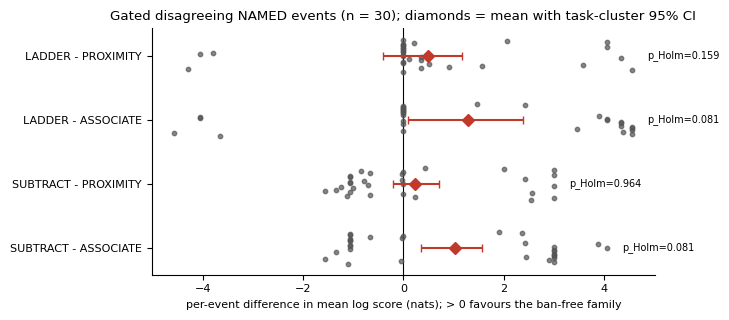

12:39:11|INFO   |figure forest_logscore_differences shown


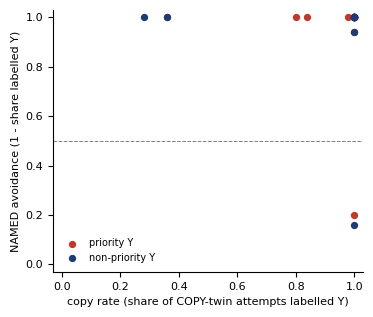

12:39:11|INFO   |figure copy_rate_vs_avoidance shown


In [25]:
# exposure/figures.py (subset): the house style, the forest plot and copy rate vs avoidance
# matplotlib.use("Agg")  -> notebook: keep the inline backend
plt.rcParams.update({"font.size": 8, "pdf.fonttype": 42, "ps.fonttype": 42, "axes.spines.top": False,
                     "axes.spines.right": False})
ROLE_COLORS = {"Y (shown)": "#9e9e9e", "default": "#1f3b73", "other survivor": "#4daf4a", "'other'": "#e6a023",
               "invalid": "#d9d9d9"}


def _save(fig, name: str) -> None:
    # notebook: show the figure inline (the original writes figures/{name}.png and .pdf)
    plt.show()
    plt.close(fig)
    logger.info(f"figure {name} shown")


def _short(label: str) -> str:
    return label.replace("_", " ")[:14]


def forest(named: list[dict], res: dict) -> None:
    sel = [e for e in named if e["gate_pass"] and e["disagreeing"]]
    if not sel:
        return
    fig, ax = plt.subplots(figsize=(6.5, 3.2))
    for i, (a, b) in enumerate(c1.TEST_PAIRS):
        d = [e["logscore"][a] - e["logscore"][b] for e in sel]
        y = np.full(len(d), i) + np.linspace(-0.25, 0.25, len(d)) if len(d) > 1 else np.full(len(d), i)
        ax.scatter(d, y, s=10, color="#555555", alpha=0.7, zorder=3)
        tests = res["tests"].get("tests") if res["tests"].get("run") else None
        mean = float(np.mean(d))
        if tests:
            t = tests[i]
            ax.errorbar(mean, i, xerr=[[mean - t["ci95_task_cluster"][0]], [t["ci95_task_cluster"][1] - mean]],
                        fmt="D", color="#c0392b", capsize=3, zorder=4)
            ax.text(ax.get_xlim()[1] if False else max(d) + 0.3, i, f"p_Holm={t['p_holm']:.3f}", va="center", fontsize=7)
        else:
            ax.scatter([mean], [i], marker="D", color="#c0392b", zorder=4)
    ax.axvline(0, color="black", lw=0.8)
    ax.set_yticks(range(len(c1.TEST_PAIRS)))
    ax.set_yticklabels([f"{a} - {b}" for a, b in c1.TEST_PAIRS])
    ax.set_xlabel("per-event difference in mean log score (nats); > 0 favours the ban-free family")
    ax.set_title(f"Gated disagreeing NAMED events (n = {len(sel)}); diamonds = mean with task-cluster 95% CI")
    _save(fig, "forest_logscore_differences")


def copy_vs_avoidance(meta: dict, arms: dict) -> None:
    xs, ys, pr = [], [], []
    for key, m in meta.items():
        a = arms.get(key, {})
        if "copy" in a and "named" in a:
            xs.append(a["copy"]["Y_share"])
            ys.append(a["named"]["avoidance"])
            pr.append(m["priority"])
    if not xs:
        return
    fig, ax = plt.subplots(figsize=(4, 3.4))
    for p, c, lab in [(True, "#c0392b", "priority Y"), (False, "#1f3b73", "non-priority Y")]:
        ax.scatter([x for x, q in zip(xs, pr) if q == p], [y for y, q in zip(ys, pr) if q == p], s=18, color=c, label=lab)
    ax.axhline(0.5, color="gray", lw=0.7, ls="--")
    ax.set_xlabel("copy rate (share of COPY-twin attempts labelled Y)")
    ax.set_ylabel("NAMED avoidance (1 - share labelled Y)")
    ax.set_xlim(-0.03, 1.03)
    ax.set_ylim(-0.03, 1.03)
    ax.legend(frameon=False, fontsize=7)
    _save(fig, "copy_rate_vs_avoidance")


forest(named, res_named)

# copy rate = a COPY-twin statistic (published, per-program); NAMED avoidance = re-derived from the events.
# These are the only two fields copy_vs_avoidance reads from `arms`.
copy_rate = data["metadata"]["published_other_reports"].get("copy_rate", {})
meta_fig = {f"{e['task']}:{e['Y']}": {"priority": e["priority"]} for e in named}
arms_fig = {f"{e['task']}:{e['Y']}": {"copy": {"Y_share": copy_rate[f"{e['task']}:{e['Y']}"]["Y_share"]},
                                       "named": {"avoidance": e["avoidance"]}}
            for e in named if f"{e['task']}:{e['Y']}" in copy_rate}
copy_vs_avoidance(meta_fig, arms_fig)

### What replaces the banned algorithm?

One row per banned algorithm Y, for both ban wordings. Each bar splits the 50 programs into four parts:
- Y kept despite the ban (grey);
- the task's **context-free default** (navy);
- another catalogue algorithm (green);
- something outside the catalogue (orange).

The text to the right names the modal replacement, followed by the families whose committed top-1 named it. In most rows the navy segment dominates and the bracket contains **L**: the ban sends the model back to its default.

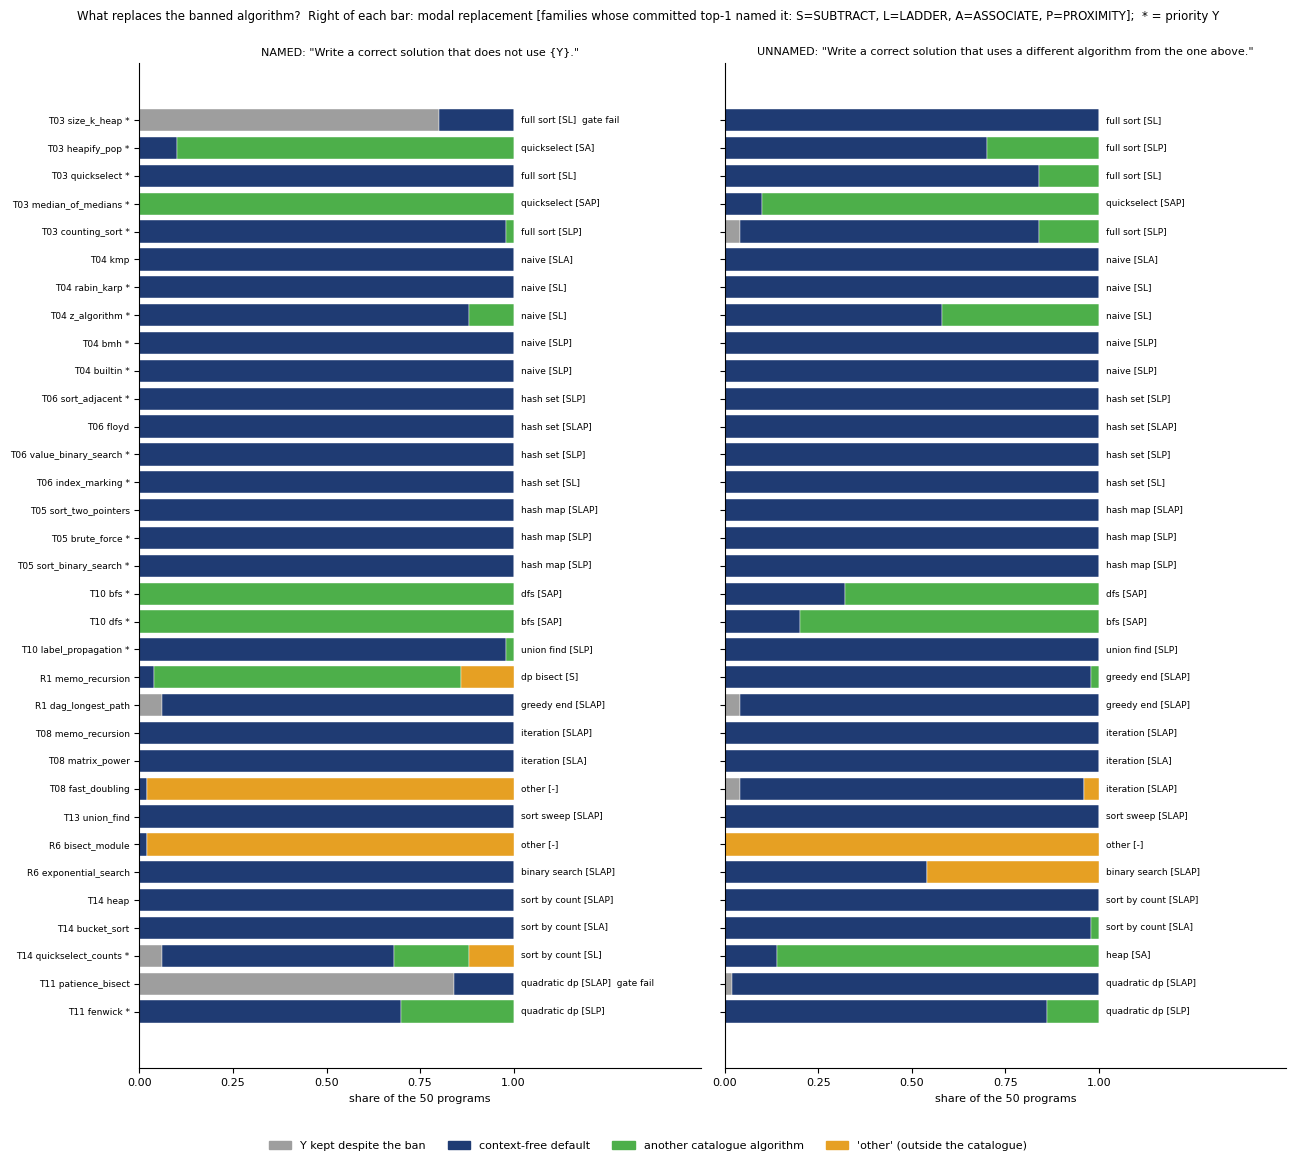

In [26]:
# Notebook figure: what replaces the banned algorithm?  One row per banned Y, shares of the 50 programs of each arm
roles = ["Y (shown)", "default", "other survivor", "'other'"]


def _composition(e):
    n = e["n_attempts"]
    land = e["landing_counts"]
    return [(e["n_attempts"] - e["n_nonY"]) / n,                                            # Y kept despite the ban
            land.get(e["default"], 0) / n,                                                  # the context-free default
            sum(v for k, v in land.items() if k in e["survivors"] and k != e["default"]) / n,  # another catalogue mode
            land.get(c1.OTHER, 0) / n]                                                       # outside the catalogue


fig, axes = plt.subplots(1, 2, figsize=(13, 0.3 * len(named) + 1.8), sharey=True)
for ax, (arm, evs_arm) in zip(axes, (("NAMED", named), ("UNNAMED", unnamed))):
    for i, e in enumerate(evs_arm):
        left = 0.0
        for role, share in zip(roles, _composition(e)):
            ax.barh(i, share, left=left, color=ROLE_COLORS[role], edgecolor="white", linewidth=0.3, height=0.8)
            left += share
        who = "".join(f[0] for f in c1.FAMILIES if set(e["top1"][f]) & set(e["modal"]))  # S/L/A/P whose top-1 hit
        ax.text(1.02, i, f"{_short('/'.join(e['modal']) or '-')} [{who or '-'}]" + ("" if e["gate_pass"] else "  gate fail"),
                va="center", fontsize=6.5)
    ax.set_yticks(range(len(evs_arm)))
    ax.set_yticklabels([f"{e['task']} {e['Y']}{' *' if e['priority'] else ''}" for e in evs_arm], fontsize=6.5)
    ax.set_xlim(0, 1.5)
    ax.set_xticks([0, 0.25, 0.5, 0.75, 1.0])
    ax.set_xlabel("share of the 50 programs")
    ax.set_title(f"{arm}: \"{WORDINGS[arm.lower()].format(x='{Y}')}\"", fontsize=8)
axes[0].invert_yaxis()
fig.legend([plt.Rectangle((0, 0), 1, 1, color=ROLE_COLORS[r]) for r in roles],
           ["Y kept despite the ban", "context-free default", "another catalogue algorithm", "'other' (outside the catalogue)"],
           loc="lower center", ncol=4, frameon=False, fontsize=8)
fig.suptitle("What replaces the banned algorithm?  Right of each bar: modal replacement [families whose committed "
             "top-1 named it: S=SUBTRACT, L=LADDER, A=ASSOCIATE, P=PROXIMITY];  * = priority Y", fontsize=8.5)
fig.tight_layout(rect=(0, 0.035, 1, 0.98))
plt.show()

### Summary figure

- **(a) Snap-back.** The share of attempts equal to the context-free default, by arm. COPY and the final veto round are published per-program statistics; NAMED and UNNAMED are re-derived from the events.
- **(b)** Events won by each family under the frozen advance rule.
- **(c)** How often each committed top-1 named the observed modal replacement.
- **(d)** How the "≥ 3 wins" rule behaves when there is nothing to find, next to a proper Holm-Wilcoxon test.

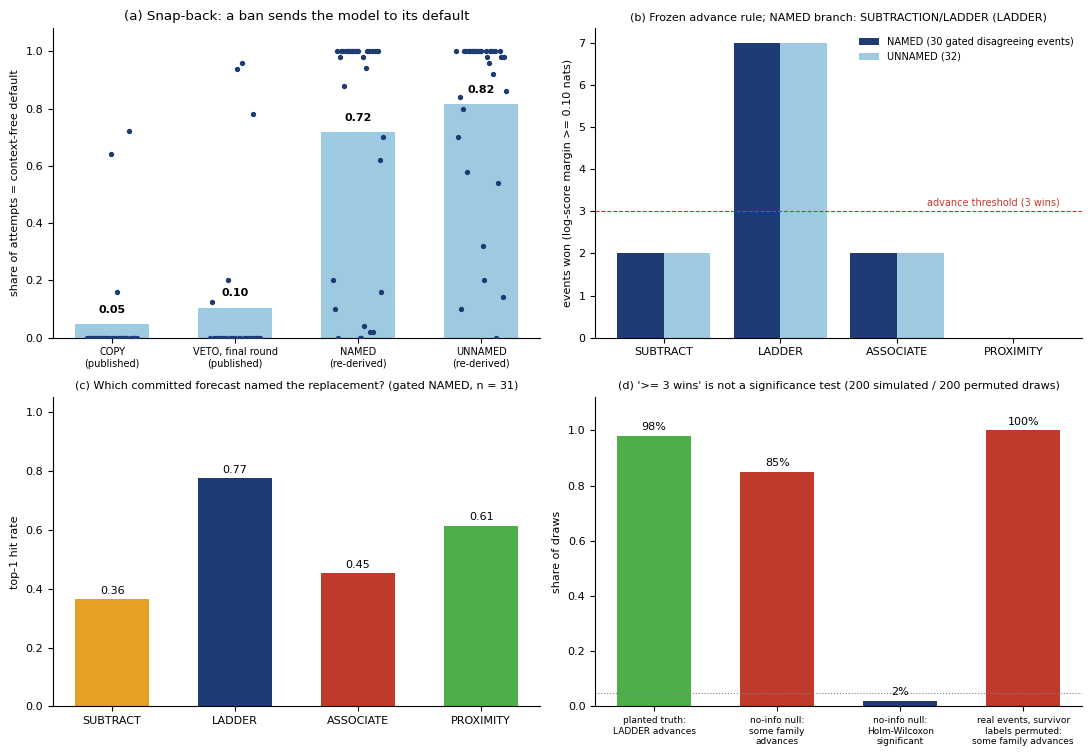

In [27]:
# Notebook summary figure: snap-back, the frozen contest, forecast accuracy, and what the counting rule is worth
FAM = c1.FAMILIES
fig, axs = plt.subplots(2, 2, figsize=(11, 7.6))

# (a) share of attempts equal to the context-free default, per arm (bars = mean over Y, dots = one Y each)
pub_dsa = data["metadata"]["published_other_reports"].get("default_share_by_arm", {})
keys_now = [f"{e['task']}:{e['Y']}" for e in named if f"{e['task']}:{e['Y']}" in pub_dsa]
cols = ([("COPY\n(published)", [pub_dsa[k]["copy"] for k in keys_now]),
         ("VETO, final round\n(published)", [pub_dsa[k]["veto_final"] for k in keys_now])] if keys_now else [])
cols += [("NAMED\n(re-derived)", [e["default_share"] for e in named]),
         ("UNNAMED\n(re-derived)", [e["default_share"] for e in unnamed])]
ax = axs[0, 0]
for i, (lab, vals) in enumerate(cols):
    v = [x for x in vals if x is not None and not math.isnan(x)]
    mu = float(np.mean(v)) if v else 0.0
    ax.bar(i, mu, color="#9ecae1", width=0.6)
    ax.scatter(np.full(len(v), i) + np.linspace(-0.2, 0.2, len(v)), v, s=8, color="#1f3b73", zorder=3)
    ax.text(i, min(mu + 0.04, 1.02), f"{mu:.2f}", ha="center", fontsize=8, fontweight="bold")
ax.set_xticks(range(len(cols)))
ax.set_xticklabels([c[0] for c in cols], fontsize=7)
ax.set_ylim(0, 1.08)
ax.set_ylabel("share of attempts = context-free default")
ax.set_title("(a) Snap-back: a ban sends the model to its default")

# (b) frozen advance rule: events won per family
ax = axs[0, 1]
x = np.arange(len(FAM))
ax.bar(x - 0.2, [res_named["rule"]["wins"][f] for f in FAM], width=0.4, color="#1f3b73",
       label=f"NAMED ({res_named['n_gated_disagreeing']} gated disagreeing events)")
ax.bar(x + 0.2, [res_unnamed["rule"]["wins"][f] for f in FAM], width=0.4, color="#9ecae1",
       label=f"UNNAMED ({res_unnamed['n_gated_disagreeing']})")
ax.axhline(c1.MIN_WINS, color="#c0392b", ls="--", lw=0.8)
ax.text(len(FAM) - 0.6, c1.MIN_WINS + 0.15, "advance threshold (3 wins)", color="#c0392b", ha="right", fontsize=7)
ax.set_xticks(x)
ax.set_xticklabels(FAM)
ax.set_ylabel("events won (log-score margin >= 0.10 nats)")
ax.set_title(f"(b) Frozen advance rule; NAMED branch: {res_named['branch']}", fontsize=8)
ax.legend(frameon=False, fontsize=7, loc="upper right")

# (c) how often each family's committed top-1 named the observed modal replacement
ax = axs[1, 0]
hv = [hits[f] if hits[f] is not None else 0.0 for f in FAM]
ax.bar(x, hv, color=["#e6a023", "#1f3b73", "#c0392b", "#4daf4a"], width=0.6)
for i, v in enumerate(hv):
    ax.text(i, v + 0.02, f"{v:.2f}", ha="center", fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels(FAM)
ax.set_ylim(0, 1.05)
ax.set_ylabel("top-1 hit rate")
ax.set_title(f"(c) Which committed forecast named the replacement? (gated NAMED, n = {len(gated)})", fontsize=8)

# (d) the >= 3-wins counting rule vs a real test, on simulated and on permuted data
ax = axs[1, 1]
bars = [("planted truth:\nLADDER advances", calib["planted_advance_rate"], "#4daf4a"),
        ("no-info null:\nsome family\nadvances", calib["null_any_family_advances_rate"], "#c0392b"),
        ("no-info null:\nHolm-Wilcoxon\nsignificant", calib["null_holm_any_significant_rate"], "#1f3b73"),
        ("real events, survivor\nlabels permuted:\nsome family advances",
         plac["label_permutation"]["share_any_family_advances"], "#c0392b")]
ax.bar(range(len(bars)), [b[1] for b in bars], color=[b[2] for b in bars], width=0.6)
for i, b in enumerate(bars):
    ax.text(i, b[1] + 0.02, f"{b[1]:.0%}", ha="center", fontsize=8)
ax.axhline(0.05, color="gray", ls=":", lw=0.8)
ax.set_xticks(range(len(bars)))
ax.set_xticklabels([b[0] for b in bars], fontsize=6.5)
ax.set_ylim(0, 1.12)
ax.set_ylabel("share of draws")
ax.set_title(f"(d) '>= 3 wins' is not a significance test ({N_CALIB_DRAWS} simulated / "
             f"{N_PERMUTATION_DRAWS} permuted draws)", fontsize=8)
fig.tight_layout()
plt.show()

## Take-aways

With the full configuration (all 33 Y, original resampling budgets), the cells above reproduce the published frozen analysis of the Qwen3-8B exposure stratum.

- **Bans are obeyed, and they snap back to the default.**
  - NAMED avoidance averages 0.95.
  - The default's share of attempts rises from 0.05 under COPY to 0.72 under NAMED and 0.82 under UNNAMED.
  - In 24 of 31 gated NAMED events, the modal replacement *is* the context-free default.
  - Naming Y adds little beyond "use something different".
- **The frozen C1 verdict is `SUBTRACTION/LADDER (LADDER)`.**
  - LADDER wins 7 of the 30 gated disagreeing NAMED events, SUBTRACT and ASSOCIATE 2 each, PROXIMITY 0.
  - LADDER's top-1 names the modal replacement in 0.77 of gated events. The model's own "standard alternative to Y" (ASSOCIATE) manages 0.45.
- **Read the verdict with its caveats.**
  - No Holm-corrected Wilcoxon test reaches p < 0.05 on NAMED, although the task-cluster CIs of SUBTRACT − ASSOCIATE and LADDER − ASSOCIATE exclude 0.
  - The ≥ 3-wins counting rule advances *some* family in most no-information simulations and in every label-permutation draw, so the branch label alone is weak evidence.
  - SUBTRACT is defined for only 4 of 33 Y, because the n-gram veto rarely removes Y.
- **For the question of steering a model toward novel solutions:** forbidding the solution the model was just shown does not push it toward a new or "associated" alternative. It mostly returns the model to the answer it gives with no context at all. On this evidence, a ban subtracts; it does not aim.

*Not re-run here:* generation (`stage1`/`stage2`: vLLM + Qwen3-8B on a GPU, about 1 GPU-hour on an L4), labelling, and the per-program reports. Those are copy rates, veto diagnostics, the W1–W4 template arm and C1-exposure; their published values are in `data["metadata"]`.